# ANI · Asistente Normativo Institucional — v8 (EP2)
**Liceo Polivalente Guillermo Labarca Hubertson** · ISY0101 Ingeniería de Soluciones con IA (DUOC UC) · Felipe y Adolfo

Agente con **LLM + RAG** que responde dudas de apoderados sobre el *Reglamento de Evaluación y Promoción 2026*, el *Reglamento Interno de Convivencia Escolar 2026* y el *Decreto 67/2018*, citando documento, ubicación y página. En la v8 además **acompaña trámites**: decide qué corresponde según el reglamento, pide confirmación y deja listo el siguiente paso (registro para UTP, borrador de solicitud y recordatorio del plazo).

### Antes de ejecutar
1. **GPU:** *Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU → Guardar* (sin GPU funciona, pero lento).
2. **Clave de Gemini:** ícono 🔑 (barra izquierda) → *Secretos* → `GEMINI_API_KEY` con *Acceso al notebook* activado.
3. **Carpeta `ANI` en Drive** con: `Reglamento_Evaluacion_2026.pdf`, `Reglamento_Convivencia.pdf`, `Decreto_67_2018.pdf`, `logo_liceo.png`, `logo_slep.png` y `ANI_set_preguntas_prueba.xlsx`. La memoria de largo plazo (`ani_memoria.db`) se crea sola en esa carpeta.
4. *Entorno de ejecución → Ejecutar todas.* La celda 6b corre las pruebas automáticas y la celda 7 entrega el link de la interfaz, con dos pestañas: **Consulta** y **Trámites**.

### Arquitectura
| Componente | Implementación |
|---|---|
| Fragmentación | PyMuPDF, por sección / artículo / punto / protocolo, 800 caracteres con solape de 150, con páginas |
| Recuperación | Multi-consulta (consulta del agente + pregunta original) · híbrida semántica (e5-small + ChromaDB) y léxica (BM25) con fusión RRF · reranker cross-encoder multilingüe |
| Agente | LangChain (`AgentExecutor` + `create_tool_calling_agent`) con Gemini: 6 herramientas de consulta y razonamiento (norma interna, Decreto 67, asistencia, plazos hábiles, promoción según Art. 10 y consulta de casos) y respaldo de modelos ante 429/503 |
| Trámites | Planner de 11 reglas del reglamento (reprogramación, promoción y plazo de notas), re-planificación cuando cambian los datos y confirmación humana antes de escribir |
| Escritura | Registro de la solicitud para UTP, Dirección o Convivencia · borrador formal con la norma citada · recordatorio del plazo (`.ics`) |
| Memoria | Corto plazo: ventana de los últimos 6 turnos · Largo plazo: casos en SQLite dentro de Drive, con código de caso y borrado a los 60 días · Semántica: el índice RAG |
| Controles | búsqueda obligatoria · re-búsqueda antes de rechazar · ocultamiento de RUT/correo/teléfono · nada se escribe sin confirmación ni con datos personales · trazabilidad |
| Pruebas | 11 pruebas automáticas sin costo de cuota (celda 6b) · evaluación con 40 preguntas y juez LLM (celdas 9 y 10) |
| Interfaz | Gradio con pestañas **Consulta** (chat, fuentes y 👍/👎 con comentario revisado por UTP) y **Trámites** (formulario, plan, archivos descargables y retomar caso) |

> El historial de iteraciones (v1 → v7), con el diagnóstico y la justificación de cada cambio, está en el repositorio `felipits/ANI-asistente-normativo` (`docs/BITACORA.md`). La v8 agrega el agente con LangChain, los trámites y la memoria de largo plazo para la EP2.

## 1 · Configuración

In [2]:
# ============================================================
# 1 · CONFIGURACIÓN: librerías, Drive, GPU y Gemini
# ============================================================
#!pip install -q -U pymupdf chromadb sentence-transformers rank_bm25 holidays openpyxl gradio google-genai
!pip install -q -U pymupdf chromadb sentence-transformers rank_bm25 holidays openpyxl gradio google-genai langchain-text-splitters langchain-classic langchain-google-genai

import os, re, json, glob, time, csv, html, base64, unicodedata
import datetime as dt
from zoneinfo import ZoneInfo
import torch
from google.colab import drive, userdata
from google import genai
from google.genai import types

# ---------- Drive: busca la carpeta ANI (sirve para la cuenta de cualquier integrante) ----------
drive.mount("/content/drive")
carpetas = [c for c in glob.glob("/content/drive/MyDrive/**/ANI", recursive=True)
            if any(os.path.exists(os.path.join(c, f"Decreto_67_2018{ext}")) for ext in (".md", ".pdf"))]
if not carpetas:
    raise FileNotFoundError("No encontré la carpeta ANI con los PDF en tu Drive.")
CARPETA = carpetas[0]
print("📁 Carpeta:", CARPETA)

# ---------- GPU (el reranker es ~50 veces más rápido con GPU) ----------
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
print("⚡ GPU activa" if DISPOSITIVO == "cuda" else
      "⚠️ Sin GPU: ANI funcionará, pero lento. Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU")

# ---------- Gemini (la clave va en 🔑 Secretos como GEMINI_API_KEY, nunca en el código) ----------
client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
MODELOS = ["gemini-3.1-flash-lite", "gemini-3.5-flash-lite", "gemini-3.8-flash"]   # el más rápido primero; los otros, de respaldo
HOY = dt.datetime.now(ZoneInfo("America/Santiago")).date().isoformat()
PROBAR = False   # True para ver pruebas que gastan cuota de Gemini
print("📅 Fecha (hora de Chile):", HOY)

# ---------- EP2: agente con LangChain + memoria de largo plazo ----------
os.environ["GOOGLE_API_KEY"] = userdata.get("GEMINI_API_KEY")   # langchain-google-genai la lee de aquí

# Reglas del Reglamento de Evaluación 2026 que usa el planner de trámites
ASISTENCIA_MINIMA = 85.0          # Art. 10, 2) a)
PROMEDIO_UNA_REPROBADA = 4.5      # Art. 10, 1) b)
PROMEDIO_DOS_REPROBADAS = 5.0     # Art. 10, 1) c)
DIAS_ENTREGA_NOTAS = 10           # resultados informados en máximo 10 días hábiles
DIAS_JUSTIFICAR_INASISTENCIA = 5  # Reglamento de Convivencia: certificado en máximo 5 días hábiles

# Memoria de largo plazo en Drive: /content se borra al cerrar Colab, Drive no
DB_PATH = os.path.join(CARPETA, "ani_memoria.db")
SALIDAS = "/content/salidas"      # borradores y recordatorios descargables
os.makedirs(SALIDAS, exist_ok=True)
DIAS_RETENCION_CASOS = 60         # Ley 21.719: los casos se borran a los 60 días
VENTANA = 6                       # turnos que el agente ve completos (memoria de corto plazo)


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/base_command.py", line 109, in _run_wrapper
    status = _inner_run()
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/base_command.py", line 102, in _inner_run
    return self.run(options, args)
           ~~~~~~~~^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/req_command.py", line 106, in wrapper
    return func(self, options, args)
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/commands/install.py", line 541, in run
    conflicts = self._determine_conflicts(to_install)
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/commands/install.py", line 662, in _determine_conflicts
    return check_install_conflicts(to_install)
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/operations/check.py", line 110, in check_install_conflicts
    package_set, _ = create_package_set_from_installed()
            

## 2 · Documentos → fragmentos citables

In [3]:
# ============================================================
# 2 · DOCUMENTOS → FRAGMENTOS CITABLES
#   Cada fragmento guarda documento, ubicación (sección / artículo / punto / protocolo) y páginas,
#   para que ANI pueda citar de dónde sale cada dato. Fragmentos de 800 caracteres con 150 de solape.
# ============================================================
import pymupdf


DESFASE_DOC = {"Reglamento de Evaluación y Promoción 2026": -1,
               "Reglamento Interno de Convivencia Escolar 2026": -1}
DOCUMENTOS = [
    # archivo, nombre para citar, tipo (interna/externa), año, páginas de portada/índice que se saltan
    ("Reglamento_Evaluacion_2026.pdf", "Reglamento de Evaluación y Promoción 2026", "interna", 2026, 3),
    ("Reglamento_Convivencia.pdf",     "Reglamento Interno de Convivencia Escolar 2026", "interna", 2026, 3),
    ("Decreto_67_2018.pdf",            "Decreto 67/2018 (MINEDUC)", "externa", 2018, 0),
]

# Los reglamentos numeran sus páginas sin contar la portada: la página impresa es la del PDF menos 1.
# ANI cita la página impresa, que es la que el apoderado ve escrita en el documento.
DESFASE_PAGINA = {"Reglamento_Evaluacion_2026": -1, "Reglamento_Convivencia": -1}

ETIQUETA_CON_PASO = False   # True: "… · Paso 2 Citación…" en la etiqueta; False: el paso solo corta, no etiqueta

# ---------- 1. Limpieza de líneas ----------
RUIDO = [
    re.compile(r"^\s*\d{1,3}\s*$"),                      # números de página sueltos
    re.compile(r"^\s*[•●▪§\-–]\s*$"),                    # viñetas vacías
    re.compile(r"\.{5,}"),                               # líneas del índice (.......)
    re.compile(r"^Decreto 67, EDUCACI"),                 # encabezado BCN
    re.compile(r"^Biblioteca del Congreso Nacional"),    # encabezado BCN
    re.compile(r"^página \d+ de \d+"),                   # pie BCN
]

def limpiar(linea):
    linea = linea.replace("\u00a0", " ").strip()
    if not linea or any(p.search(linea) for p in RUIDO):
        return None
    return linea

# ---------- 2. Detección de títulos según el documento ----------
ART  = re.compile(r"^Art[íi]culo\s+(\d+)\s*[°º]?\s*\.?\s*-")
SEC_EVAL = re.compile(r"^(\d{1,2})\s*\.-?\s*([A-ZÁÉÍÓÚÑ][A-ZÁÉÍÓÚÑ ,;()\.]{4,})$")
ROMANO = re.compile(r"^([IVX]{1,4})\s*\.\s*(.{4,})$")
SUBSEC = re.compile(r"^(\d{1,2}\.\d{1,2}(?:\.\d{1,2}){0,2})\.?(?:\s+([A-ZÁÉÍÓÚÑ¿].*)|\s*)$")
PASO   = re.compile(r"^(Paso|Etapa)\s+(\d{1,2})\s*[:\.]?\s*(.*)$", re.IGNORECASE)   # "Paso 1:", "PASO 1.", "Etapa 2."
APARTADO = re.compile(r"^[A-ZÁÉÍÓÚÑ][A-ZÁÉÍÓÚÑ ,;()\-]{14,}:?$")              # subtítulo en mayúsculas dentro de un protocolo
PROTO  = re.compile(r"^(\d{1,2})\s*[\.\-]\s*(PROTOCOLO\b.*|Protocolo\b.*)$")

TITULOS_FIJOS = {14: "Protocolo de manejo de estudiantes con tratamiento farmacológico"}  # título partido en el PDF

def titulo_corto(t, n=90):
    t = re.sub(r"\s+", " ", t).strip(" .:")
    return t[:n]

MARCA_PAGINA = re.compile(r"^\s*<!--\s*p[áa]gina\s+(\d+)\s*-->\s*$", re.IGNORECASE)

def leer_paginas(ruta):
    """Entrega (número de página, líneas de esa página), venga de un .md o de un .pdf."""
    if ruta.endswith(".pdf"):
        for num_pag, pagina in enumerate(pymupdf.open(ruta), start=1):
            yield num_pag, pagina.get_text().split("\n")
        return
    num_pag, lineas = 1, []
    with open(ruta, encoding="utf-8") as fh:
        for linea in fh.read().split("\n"):
            m = MARCA_PAGINA.match(linea)
            if m:                                   # empieza una página nueva
                if lineas:
                    yield num_pag, lineas
                num_pag, lineas = int(m.group(1)), []
            else:
                lineas.append(linea)
    if lineas:
        yield num_pag, lineas

def segmentar(ruta, nombre, tipo, anio, saltar=0):
    desfase = DESFASE_PAGINA.get(os.path.splitext(os.path.basename(ruta))[0], 0)
    secciones = []
    ctx = {"seccion": "", "protocolo": "", "punto": "", "apartado": "", "paso": "", "articulo": ""}
    num_sec, num_proto = 0, 0   # los números de sección/protocolo solo pueden avanzar
    actual = {"texto": [], "pags": [], "pag_ini": 1, "etiqueta": "Inicio"}
    num_suelto = None
    pendiente = None   # título partido en dos líneas (ej: "4.7" y el título abajo)

    def etiqueta():
      partes = []
      if ctx["protocolo"]:
          partes.append(ctx["protocolo"])
      elif ctx["seccion"]:
          partes.append(ctx["seccion"])
      if ctx["punto"]:
          partes.append(ctx["punto"])
      if ctx["apartado"]:
          partes.append(ctx["apartado"])
      if ctx["paso"] and ETIQUETA_CON_PASO:
          partes.append(ctx["paso"])
      if ctx["articulo"]:
          partes.append(ctx["articulo"])
      return " · ".join(partes) or "Inicio"

    def agregar(linea, pag):
        actual["texto"].append(linea)
        actual["pags"].append(pag + desfase)

    def cerrar(pag):
        if actual["texto"]:
            # mapa de páginas: [(posición del carácter donde empieza una página, número de página), ...]
            mapa, pos = [], 0
            for linea, p in zip(actual["texto"], actual["pags"]):
                if not mapa or mapa[-1][1] != p:
                    mapa.append((pos, p))
                pos += len(linea) + 1                      # +1 por el "\n" que las une
            secciones.append({"etiqueta": actual["etiqueta"], "texto": "\n".join(actual["texto"]),
                              "pag_ini": actual["pags"][0], "pag_fin": actual["pags"][-1], "mapa": mapa})
        actual.update({"texto": [], "pags": [], "etiqueta": etiqueta()})

    for num_pag, lineas in leer_paginas(ruta):
        if num_pag <= saltar:
            continue
        for bruta in lineas:
            linea = limpiar(bruta)
            if linea is None:
                continue
            if "Convivencia" in ruta and re.fullmatch(r"\d{1,2}\s*[\.\-]", linea):
                num_suelto = linea                  # ej: "14." y en la línea siguiente "Protocolo de..."
                continue
            if "Convivencia" in ruta and num_suelto:
                if linea.lower().startswith("protocolo"):
                    linea = f"{num_suelto} {linea}"
                else:
                    agregar(num_suelto, num_pag)       # antes: actual["texto"].append(num_suelto)
                num_suelto = None
            if pendiente:                       # completar título partido
                linea_titulo = f"{pendiente} {linea}"
                pendiente = None
                cerrar(num_pag)
                ctx["punto"] = f"punto {titulo_corto(linea_titulo, 80)}"
                ctx["apartado"], ctx["paso"] = "", ""
                actual["etiqueta"] = etiqueta()
                agregar(linea_titulo, num_pag)     # antes: actual["texto"].append(linea_titulo)
                continue

            es_titulo = False
            m_art = ART.match(linea)
            if m_art:
                cerrar(num_pag); es_titulo = True
                ctx["articulo"] = f"Art. {m_art.group(1)}°"
                if tipo == "externa":
                    ctx["punto"] = ""

            elif "Evaluacion" in ruta and SEC_EVAL.match(linea):
                m = SEC_EVAL.match(linea)
                cerrar(num_pag); es_titulo = True
                n = int(m.group(1))
                if n > num_sec:                    # nueva sección del reglamento
                    num_sec = n
                    ctx["seccion"] = f"Sección {n} {titulo_corto(m.group(2), 60)}"
                    ctx["punto"], ctx["articulo"] = "", ""
                else:                              # numeración interna (ej. sección TP)
                    ctx["punto"] = f"punto {n} {titulo_corto(m.group(2), 60)}"

            elif "Convivencia" in ruta:
                m_p, m_r, m_s = PROTO.match(linea), ROMANO.match(linea), SUBSEC.match(linea)
                if not num_proto and linea.upper().startswith("PROTOCOLO DE ALUMNAS EN SITUACI"):
                    m_p = re.match(r"(1)(.*)", "1" + linea)       # el protocolo 1 no trae número
                if m_p and num_proto < int(m_p.group(1)) <= 17:
                    num_proto = int(m_p.group(1))
                    cerrar(num_pag); es_titulo = True
                    titulo = TITULOS_FIJOS.get(num_proto, m_p.group(2))
                    ctx["protocolo"] = f"Protocolo {num_proto}: {titulo_corto(titulo, 70)}"
                    ctx["punto"], ctx["apartado"], ctx["paso"] = "", "", ""
                elif m_r and not ctx["protocolo"]:
                    cerrar(num_pag); es_titulo = True
                    ctx["seccion"] = f"Título {m_r.group(1)} {titulo_corto(m_r.group(2), 60)}"
                    ctx["punto"], ctx["apartado"], ctx["paso"] = "", "", ""
                elif PASO.match(linea) and ctx["protocolo"]:
                    m_paso = PASO.match(linea)
                    cerrar(num_pag); es_titulo = True
                    ctx["paso"] = f"{m_paso.group(1).capitalize()} {m_paso.group(2)} {titulo_corto(m_paso.group(3), 50)}".strip()
                elif APARTADO.match(linea) and ctx["protocolo"]:
                    cerrar(num_pag); es_titulo = True
                    ctx["apartado"], ctx["paso"] = titulo_corto(linea, 60).capitalize(), ""
                elif m_s and len(linea) < 140:
                    if not (m_s.group(2) or "").strip():
                        pendiente = m_s.group(1)   # el título viene en la línea siguiente
                        continue
                    cerrar(num_pag); es_titulo = True
                    ctx["punto"] = f"punto {m_s.group(1)} {titulo_corto(m_s.group(2) or '', 70)}"
                    ctx["apartado"], ctx["paso"] = "", ""

            if es_titulo:
                actual["etiqueta"] = etiqueta()
            agregar(linea, num_pag)            # antes: actual["texto"].append(linea)   (la última, antes de cerrar(doc.page_count))
    cerrar(doc.page_count if "doc" in locals() else num_pag)   # .md no abre PDF: cierra con la última página leída

    for s in secciones:
        s.update({"documento": nombre, "tipo": tipo, "anio": anio})
    return [s for s in secciones if len(s["texto"]) > 80]

# ---------- 3. Cortar secciones en fragmentos (recursivo, con página exacta) ----------
from langchain_text_splitters import RecursiveCharacterTextSplitter

UNIR = re.compile(r"\n(?![a-zñ]\)\s)(?=[a-záéíóúñ,;])")   # une renglones cortados, pero NO los ítems "a) b) k)"

SEPARADORES = [
    r"\n(?=[a-zñ]\)\s)",      # 1. ítems con letra: a) b) ... k)
    r"\n(?=•)",               # 2. viñetas
    r"\n",                    # 3. cualquier salto de línea
    r"(?<=[\.;:])\s",         # 4. fin de oración
    r"\s",                    # 5. espacio (nunca a mitad de palabra)
]

def crear_cortador(tam=800, solape=150):
    return RecursiveCharacterTextSplitter(chunk_size=tam, chunk_overlap=solape, separators=SEPARADORES,
                                          is_separator_regex=True, add_start_index=True)
def pagina_en(mapa, pos):
    """Página donde cae el carácter `pos`, según el mapa de la sección."""
    pag = mapa[0][1]
    for inicio, p in mapa:
        if inicio > pos:
            break
        pag = p
    return pag
def fragmentar(seccion, cortador, minimo=120):
    texto = UNIR.sub(" ", seccion["texto"])        # cambia "\n" por " ": mismo largo, el mapa sigue sirviendo
    trozos = [(d.metadata["start_index"], d.metadata["start_index"] + len(d.page_content))
              for d in cortador.create_documents([texto])]
    # pegar trozos diminutos (un título solo, un resto como "PDI.") al vecino
    i = 0
    while len(trozos) > 1 and i < len(trozos):
        ini, fin = trozos[i]
        if fin - ini < minimo:
            if i + 1 < len(trozos):                  # al siguiente: el título queda con su contenido
                trozos[i:i+2] = [(ini, trozos[i+1][1])]
            else:                                    # el último: al anterior
                trozos[i-1:i+1] = [(trozos[i-1][0], fin)]
            continue
        i += 1
    frs = []
    for i, (ini, fin) in enumerate(trozos):
        p1 = pagina_en(seccion["mapa"], ini)
        p2 = pagina_en(seccion["mapa"], fin - 1)
        frs.append({
            "texto": texto[ini:fin],
            "documento": seccion["documento"], "tipo": seccion["tipo"], "anio": seccion["anio"],
            "ubicacion": seccion["etiqueta"],
            "paginas": str(p1) if p1 == p2 else f"{p1}-{p2}",
            "parte": f"{i+1}/{len(trozos)}",
            "padre": seccion["id"],
        })
    return frs
# ---------- 4. Construir secciones (padres) y fragmentos (hijos) ----------
cortador = crear_cortador(800, 150)
SECCIONES, fragmentos = {}, []
for archivo, nombre, tipo, anio, saltar in DOCUMENTOS:
    base = os.path.join(CARPETA, os.path.splitext(archivo)[0])   # ej: .../ANI/Decreto_67_2018
    ruta = base + ".md" if os.path.exists(base + ".md") else base + ".pdf"
    print(f"📄 {nombre} ← {os.path.basename(ruta)}")
    secs = segmentar(ruta, nombre, tipo, anio, saltar)
    for s in secs:
        s["id"] = f"sec_{len(SECCIONES):04d}"
        SECCIONES[s["id"]] = s
    frs = [f for s in secs for f in fragmentar(s, cortador)]
    print(f"{nombre}: {len(secs)} secciones → {len(frs)} fragmentos")
    fragmentos += frs
for i, f in enumerate(fragmentos):
    f["id"] = f"frag_{i:04d}"
POR_ID = {f["id"]: f for f in fragmentos}
with open(os.path.join(CARPETA, "fragmentos_final.json"), "w", encoding="utf-8") as fh:
    json.dump(fragmentos, fh, ensure_ascii=False, indent=1)
print("Total:", len(fragmentos), "fragmentos")

📄 Reglamento de Evaluación y Promoción 2026 ← Reglamento_Evaluacion_2026.md
Reglamento de Evaluación y Promoción 2026: 39 secciones → 159 fragmentos
📄 Reglamento Interno de Convivencia Escolar 2026 ← Reglamento_Convivencia.md
Reglamento Interno de Convivencia Escolar 2026: 334 secciones → 932 fragmentos
📄 Decreto 67/2018 (MINEDUC) ← Decreto_67_2018.md
Decreto 67/2018 (MINEDUC): 25 secciones → 51 fragmentos
Total: 1142 fragmentos


## 3 · Índices (semántico, léxico y reranker)

In [4]:
# ============================================================
# 3 · ÍNDICES: semántico (embeddings + ChromaDB), léxico (BM25) y reranker
# ============================================================
import chromadb
from sentence_transformers import SentenceTransformer, CrossEncoder
from rank_bm25 import BM25Okapi

DOMINIOS = {"evaluacion":  "Reglamento de Evaluación y Promoción 2026",
            "convivencia": "Reglamento Interno de Convivencia Escolar 2026"}

# ---------- 1. Modelos locales (gratis, sin cuota) ----------
modelo_emb = SentenceTransformer("intfloat/multilingual-e5-small", device=DISPOSITIVO)
RERANKER = CrossEncoder("cross-encoder/mmarco-mMiniLMv2-L12-H384-v1", max_length=384, device=DISPOSITIVO)

def emb_pasajes(textos):
    return modelo_emb.encode(["passage: " + t for t in textos], normalize_embeddings=True,
                             batch_size=32, show_progress_bar=True).tolist()

def emb_consulta(texto):
    return modelo_emb.encode(["query: " + texto], normalize_embeddings=True).tolist()

# ---------- 2. Índice semántico: 2 colecciones (norma interna / norma externa) ----------
cliente_db = chromadb.PersistentClient(path="/content/chroma_ani")
colecciones = {}
for tipo in ["interna", "externa"]:
    nombre = f"norma_{tipo}"
    try:
        cliente_db.delete_collection(nombre)
    except Exception:
        pass
    col = cliente_db.create_collection(nombre, metadata={"hnsw:space": "cosine"})
    frs = [f for f in fragmentos if f["tipo"] == tipo]
    col.add(ids=[f["id"] for f in frs],
            documents=[f["texto"] for f in frs],
            embeddings=emb_pasajes([f"{f['documento']} | {f['ubicacion']}\n{f['texto']}" for f in frs]),
            metadatas=[{k: f[k] for k in ("documento", "tipo", "anio", "ubicacion", "paginas", "parte")} for f in frs])
    colecciones[tipo] = col
    print(f"Colección {nombre}: {col.count()} fragmentos")

# ---------- 3. Índice léxico (BM25): encuentra palabras exactas como "10 días hábiles" ----------
STOPWORDS = set("""a al algo ante antes como con cual cuales cuando de del desde donde el ella ellas ellos en entre
era es esa ese eso esta este esto estos fue ha hay la las le les lo los mas me mi mis muy no nos o para pero por que se
si sin sobre su sus te tiene tu un una uno unos y ya""".split())

def normalizar(texto):
    texto = unicodedata.normalize("NFD", texto.lower())
    texto = "".join(c for c in texto if unicodedata.category(c) != "Mn")      # quita tildes
    palabras = []
    for w in re.findall(r"[a-z0-9]+", texto):
        if w in STOPWORDS:
            continue
        if len(w) > 4 and w.endswith("es"):   w = w[:-2]                       # plurales simples
        elif len(w) > 3 and w.endswith("s"):  w = w[:-1]
        palabras.append(w)
    return palabras

INDICE = {}
for tipo in ["interna", "externa"]:
    frs = [f for f in fragmentos if f["tipo"] == tipo]
    INDICE[tipo] = {"frs": frs, "bm25": BM25Okapi([normalizar(f["ubicacion"] + " " + f["texto"]) for f in frs])}
print("Índices listos.")


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (16 outputs left out)

Batches:   0%|          | 0/35 [00:00<?, ?it/s]

Colección norma_interna: 1091 fragmentos


Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Colección norma_externa: 51 fragmentos
Índices listos.


In [5]:
# ============================================================
# 3b · PREGUNTAS HIPOTÉTICAS POR FRAGMENTO (doc2query)
#   Gemini escribe, para cada fragmento, preguntas como las haría un apoderado. Se indexan aparte y
#   apuntan a su fragmento: así "¿cuál vale, el reglamento o el decreto?" puede encontrar el Art. 3°
#   aunque no compartan palabras. Se generan UNA vez y quedan guardadas en Drive.
# ============================================================
import hashlib
import numpy as np

GENERAR_PREGUNTAS = False      # True para generar las que falten (gasta cuota de Gemini)
POR_LLAMADA = 10               # fragmentos por llamada
PAUSA_D2Q = 6                  # segundos entre llamadas (cuota gratuita)
ARCHIVO_PREG = os.path.join(CARPETA, "ANI_preguntas_hipoteticas.json")

def clave(f):
    """Identifica el fragmento por su texto, no por su id: si se re-fragmenta, solo se generan las nuevas."""
    return hashlib.md5(f["texto"].encode("utf-8")).hexdigest()[:16]

PROMPT_D2Q = """Eres apoderado o apoderada de un liceo en Chile y no conoces el vocabulario de los reglamentos.
Para CADA fragmento, escribe 3 preguntas distintas que harías y que ese fragmento responde.
Usa palabras cotidianas (notas, prueba, faltar, castigo, profe, repetir, echar del colegio), no copies frases del texto.
Si el fragmento no contiene una regla útil para un apoderado (índice, formulario, firmas, tabla vacía), devuelve [].
Responde SOLO con un JSON: {{"F1": ["...", "...", "..."], "F2": [...], ...}}

{fragmentos}"""

# ---------- 1. Generar (con retoma: lo ya generado no se vuelve a pedir) ----------
preg = json.load(open(ARCHIVO_PREG, encoding="utf-8")) if os.path.exists(ARCHIVO_PREG) else {}
pendientes = [f for f in fragmentos if clave(f) not in preg]
print(f"Preguntas guardadas: {len(preg)} fragmentos · faltan {len(pendientes)}")

def generar_lote(lote):
    texto = "\n\n".join(f"[F{i+1}] {f['documento']} | {f['ubicacion']}\n{f['texto']}" for i, f in enumerate(lote))
    cfg = types.GenerateContentConfig(temperature=0.5, response_mime_type="application/json")
    for modelo in MODELOS:
        for intento in range(3):
            try:
                out = client.models.generate_content(model=modelo, contents=PROMPT_D2Q.format(fragmentos=texto), config=cfg)
                datos = json.loads(re.sub(r"```json|```", "", out.text).strip())
                if not isinstance(datos, dict):
                    continue
                return {clave(f): [p for p in datos.get(f"F{i+1}", []) if isinstance(p, str)][:3]
                        for i, f in enumerate(lote)}
            except Exception as e:
                error = str(e)
                if "PerDay" in error:
                    break                                   # sin cuota diaria en este modelo: probar el siguiente
                if any(x in error for x in ("429", "503", "UNAVAILABLE")):
                    time.sleep(10 * (intento + 1)); continue
                if isinstance(e, json.JSONDecodeError):
                    continue
                raise
    return None

if GENERAR_PREGUNTAS:
    for i in range(0, len(pendientes), POR_LLAMADA):
        resultado = generar_lote(pendientes[i:i + POR_LLAMADA])
        if resultado is None:
            print("⛔ Sin cuota por ahora. Vuelve a ejecutar más tarde: retoma donde quedó."); break
        preg.update(resultado)
        json.dump(preg, open(ARCHIVO_PREG, "w", encoding="utf-8"), ensure_ascii=False, indent=1)
        print(f"  {min(i + POR_LLAMADA, len(pendientes))}/{len(pendientes)}")
        time.sleep(PAUSA_D2Q)

# ---------- 2. Índice de preguntas: cada pregunta apunta a su fragmento ----------
PREG_FID, PREG_TXT = [], []
for f in fragmentos:
    for p in preg.get(clave(f), []):
        PREG_FID.append(f["id"])
        PREG_TXT.append(p)
PREG_EMB = (modelo_emb.encode(["query: " + p for p in PREG_TXT], normalize_embeddings=True,
                              batch_size=64, show_progress_bar=True) if PREG_TXT else np.zeros((0, 384)))
print(f"Índice de preguntas: {len(PREG_TXT)} preguntas de {len(set(PREG_FID))} fragmentos")

Preguntas guardadas: 1094 fragmentos · faltan 0


Batches:   0%|          | 0/48 [00:00<?, ?it/s]

Índice de preguntas: 3057 preguntas de 1019 fragmentos


## 4 · Buscador final
Resultado de las iteraciones: la búsqueda híbrida subió el Context Recall de 62,5% (v1) a 78,1% (v2); la multi-consulta y el reranker, a 87,5% (v3).

In [6]:
# ============================================================
# 4 · BUSCADOR FINAL: multi-consulta + híbrido (semántico + BM25) + reranker
#   1) Busca con la consulta reformulada por el agente Y con la pregunta original del apoderado.
#   2) Para cada una combina búsqueda semántica y léxica (fusión RRF).
#   3) Un reranker (cross-encoder) relee los 20 mejores candidatos y los reordena.
#   4) Entrega 4 fragmentos del reglamento elegido + 2 del otro (por si el agente elige mal) o 4 del Decreto 67.
# ============================================================
K_INTERNA, K_EXTERNA, CUOTA_OTRO, N_CANDIDATOS = 6, 4, 2, 20
PREGUNTA_ACTUAL = {"texto": ""}      # la pregunta original del apoderado (la llena el agente)
_cache_ce = {}

def _rankings(consulta, tipo, dominio, n=30):
    idx = INDICE[tipo]
    pool = [i for i, f in enumerate(idx["frs"]) if dominio is None or f["documento"] == DOMINIOS[dominio]]
    filtro = {"documento": DOMINIOS[dominio]} if dominio else None
    r = colecciones[tipo].query(query_embeddings=emb_consulta(consulta), n_results=min(n, len(pool)), where=filtro)
    sims = {i: 1 - d for i, d in zip(r["ids"][0], r["distances"][0])}
    puntajes = idx["bm25"].get_scores(normalizar(consulta))
    lex = [idx["frs"][i]["id"] for i in sorted(pool, key=lambda i: -puntajes[i])[:n] if puntajes[i] > 0]
    return r["ids"][0], lex, sims

USAR_DOC2QUERY = True   # False para medir sin las preguntas hipotéticas

def _ranking_preguntas(consulta, tipo, dominio, n=30):
    """Fragmentos ordenados según su pregunta hipotética más parecida a la consulta."""
    if not USAR_DOC2QUERY or not PREG_TXT:
        return []
    q = np.array(emb_consulta(consulta))[0]
    sims = PREG_EMB @ q
    mejor = []
    for i in np.argsort(-sims):
        f = POR_ID[PREG_FID[i]]
        if f["tipo"] != tipo or (dominio and f["documento"] != DOMINIOS[dominio]) or f["id"] in mejor:
            continue
        mejor.append(f["id"])
        if len(mejor) == n:
            break
    return mejor

def _candidatos(consultas, tipo, dominio):
    rrf, sims = {}, {}
    for c in consultas:
        sem, lex, si = _rankings(c, tipo, dominio)
        for fid, v in si.items():
            sims[fid] = max(sims.get(fid, 0.0), v)
        for lista in (sem, lex, _ranking_preguntas(c, tipo, dominio)):
            for rango, fid in enumerate(lista):
                rrf[fid] = rrf.get(fid, 0) + 1 / (60 + rango + 1)
    return sorted(rrf, key=lambda f: -rrf[f]), sims, rrf

def _reordenar(consultas, candidatos):
    pendientes = [(q, fid) for fid in candidatos for q in consultas if (q, fid) not in _cache_ce]
    if pendientes:
        pares = [(q, f"{POR_ID[fid]['ubicacion']}. {POR_ID[fid]['texto']}") for q, fid in pendientes]
        for clave, p in zip(pendientes, RERANKER.predict(pares, batch_size=32)):
            _cache_ce[clave] = float(p)
    puntaje = {fid: max(_cache_ce[(q, fid)] for q in consultas) for fid in candidatos}
    return sorted(candidatos, key=lambda f: -puntaje[f])
UMBRAL_DUP = 0.95   # similitud a partir de la cual dos fragmentos se consideran casi idénticos
_cache_emb = {}

def intercalar(consultas, candidatos):
    """Toma por turnos el mejor de cada consulta: la pregunta original siempre queda representada."""
    _reordenar(consultas, candidatos)                       # calcula y guarda los puntajes del reranker
    listas = [sorted(candidatos, key=lambda f: -_cache_ce[(q, f)]) for q in consultas]
    orden = []
    for grupo in zip(*listas):
        for fid in grupo:
            if fid not in orden:
                orden.append(fid)
    return orden

def _vectores(ids):
    faltan = [fid for fid in ids if fid not in _cache_emb]
    if faltan:
        V = modelo_emb.encode(["passage: " + POR_ID[fid]["texto"] for fid in faltan],
                              normalize_embeddings=True, batch_size=32, show_progress_bar=False)
        for fid, v in zip(faltan, V):
            _cache_emb[fid] = v
    return [_cache_emb[fid] for fid in ids]

def _diversificar(candidatos, k):
    """Recorre los candidatos en orden y salta los casi idénticos a uno ya elegido."""
    vec = dict(zip(candidatos, _vectores(candidatos)))
    elegidos = []
    for fid in candidatos:
        if all(float(vec[fid] @ vec[e]) < UMBRAL_DUP for e in elegidos):
            elegidos.append(fid)
        if len(elegidos) == k:
            break
    return elegidos

def _hibrida(consultas, tipo, k, dominio):
    orden, sims, rrf = _candidatos(consultas, tipo, dominio)
    reordenados = intercalar(consultas, orden[:N_CANDIDATOS])
    mejores = _diversificar(reordenados, k)
    return [{**POR_ID[fid], "similitud": round(sims.get(fid, 0.0), 3), "rrf": round(rrf[fid], 4)} for fid in mejores]

# ---------- Parent-child: buscar con hijos, entregar contexto ampliado ----------
MAX_PADRE = 2000    # si la sección completa mide esto o menos, se entrega entera
VECINOS = 1         # si es más larga, se entrega el hijo + 1 vecino a cada lado

HIJOS = {}          # sección → sus fragmentos en orden
for f in fragmentos:
    HIJOS.setdefault(f["padre"], []).append(f["id"])

def _tramo(sec, ids):
    """Texto y páginas desde el primer hasta el último fragmento de `ids`, sin repetir el solape."""
    texto_sec = UNIR.sub(" ", sec["texto"])
    a = texto_sec.find(POR_ID[ids[0]]["texto"])
    b = texto_sec.find(POR_ID[ids[-1]]["texto"])
    if a == -1 or b == -1:                                     # no debería pasar; por si acaso
        return "\n".join(POR_ID[i]["texto"] for i in ids), POR_ID[ids[0]]["paginas"]
    b += len(POR_ID[ids[-1]]["texto"])
    p1, p2 = pagina_en(sec["mapa"], a), pagina_en(sec["mapa"], b - 1)
    return texto_sec[a:b], (str(p1) if p1 == p2 else f"{p1}-{p2}")

def expandir(frs):
    """Agrupa los hijos por sección y devuelve, por cada grupo, la sección entera o una ventana con vecinos."""
    grupos = {}                                                # sección → posiciones de los hijos encontrados
    for f in frs:
        grupos.setdefault(f["padre"], []).append(f)
    salida = []
    for padre, hits in grupos.items():
        sec, hermanos = SECCIONES[padre], HIJOS[padre]
        mejor = hits[0]                                        # el mejor rankeado de esa sección
        if len(sec["texto"]) <= MAX_PADRE:
            texto, pags = _tramo(sec, hermanos)
            salida.append({**mejor, "texto": texto, "paginas": pags, "ampliado": "sección completa"})
            continue
        # ventanas [pos - VECINOS, pos + VECINOS] que se fusionan si se tocan
        ventanas = []
        for pos in sorted(hermanos.index(h["id"]) for h in hits):
            ini, fin = max(0, pos - VECINOS), min(len(hermanos) - 1, pos + VECINOS)
            if ventanas and ini <= ventanas[-1][1] + 1:
                ventanas[-1][1] = max(ventanas[-1][1], fin)
            else:
                ventanas.append([ini, fin])
        for ini, fin in ventanas:
            texto, pags = _tramo(sec, hermanos[ini:fin + 1])
            salida.append({**mejor, "texto": texto, "paginas": pags, "ampliado": f"ventana {ini+1}-{fin+1} de {len(hermanos)}"})
    return salida

def buscar(consulta, tipo="interna", k=6, dominio=None, ampliar=True):
    original = PREGUNTA_ACTUAL["texto"].strip()
    consultas = [consulta] + ([original] if original and original.lower() != consulta.lower() else [])
    if tipo == "interna":
        k = max(k, K_INTERNA)
        if dominio in DOMINIOS:
            otro = [d for d in DOMINIOS if d != dominio][0]
            res = (_hibrida(consultas, tipo, k - CUOTA_OTRO, dominio) +
                   _hibrida(consultas, tipo, CUOTA_OTRO, otro))
        else:
            res = _hibrida(consultas, tipo, k, None)
    else:
        res = _hibrida(consultas, tipo, max(k, K_EXTERNA), None)
    return expandir(res) if ampliar else res

# ---------- Prueba rápida de recuperación (no gasta cuota de Gemini) ----------
pruebas = [
    ("plazo para informar y retroalimentar los resultados de las evaluaciones", "evaluacion", "no exceda los 10"),
    ("calificación mínima de aprobación", "evaluacion", "mínima de aprobación"),
    ("¿Cuántos atrasos puede tener antes de que me citen?", "convivencia", "quinto (5) atraso"),
    ("plazo para justificar inasistencia certificado médico", "evaluacion", "5 días hábiles"),
    ("aproximación de la calificación final", "evaluacion", "aproximación"),
]
print("Prueba de recuperación:")
for consulta, dominio, buscada in pruebas:
    frs = buscar(consulta, "interna", dominio=dominio)
    pos = next((i + 1 for i, f in enumerate(frs) if buscada.lower() in f["texto"].lower()), None)
    print(f"  {'✅' if pos else '❌'} {consulta[:60]:<60} → {'posición ' + str(pos) if pos else 'no encontrado'}")


Prueba de recuperación:
  ✅ plazo para informar y retroalimentar los resultados de las e → posición 1
  ✅ calificación mínima de aprobación                            → posición 1
  ✅ ¿Cuántos atrasos puede tener antes de que me citen?          → posición 3
  ✅ plazo para justificar inasistencia certificado médico        → posición 3
  ✅ aproximación de la calificación final                        → posición 1


In [7]:
# ============================================================
# 4b · COMPARACIÓN DE ESTRATEGIAS DE FRAGMENTACIÓN (RA1 · IL1.3)
#   Mide SOLO la recuperación (no usa Gemini, no gasta cuota) sobre las preguntas que tienen respuesta.
#   Uso: ajusta la configuración en la celda 2, ejecuta 2 → 3 → 4 → esta celda. Cada corrida se suma al CSV.
# ============================================================
import glob, os, re
import pandas as pd
import matplotlib.pyplot as plt

COMPARAR = False                                    # True para medir
CONFIG = "v5 · recursivo 800/150"                    # nombre de lo que estás midiendo: cámbialo en cada corrida
VARIANTES = {"sin anti-duplicados": 1.01, "anti-duplicados 0.95": 0.95}   # valores de UMBRAL_DUP a probar
TOL = 1                                              # tolerancia de página (±1), igual que la celda 10
ARCHIVO_CMP = os.path.join(CARPETA, "ANI_comparacion_fragmentacion.csv")

# ---------- 1. Funciones de medición ----------
def paginas_de(texto):
    """'19-20' -> {19, 20}; '62 / 70' -> {62, 70}; '17.0' -> {17}"""
    s = set()
    for a, b in re.findall(r"(\d+)(?:\.0)?\s*(?:[-–]\s*(\d+))?", str(texto)):
        a = int(a); b = int(b) if b else a
        s.update(range(a, b + 1))
    return s

def acierta(f, doc, pags_esp, tol):
    """El fragmento es del documento esperado y alguna de sus páginas calza con la esperada (± tol)."""
    return doc in f["documento"] and any(abs(p - q) <= tol for p in paginas_de(f["paginas"]) for q in pags_esp)

def medir(preguntas):
    filas = []
    for _, q in preguntas.iterrows():
        doc, dominio = ("Evaluaci", "evaluacion") if q["dominio"] == "evaluación" else ("Convivencia", "convivencia")
        pe = paginas_de(q["pagina"])
        PREGUNTA_ACTUAL["texto"] = q["pregunta"]
        try:
            hijos = buscar(q["pregunta"], "interna", dominio=dominio, ampliar=False)
        except TypeError:                            # notebook sin parent-child: buscar no tiene `ampliar`
            hijos = buscar(q["pregunta"], "interna", dominio=dominio)
        contexto = expandir(hijos) if "expandir" in globals() else hijos
        pos = next((i + 1 for i, f in enumerate(hijos) if acierta(f, doc, pe, TOL)), None)
        filas.append({
            "documento": "Evaluación" if doc == "Evaluaci" else "Convivencia",
            "hit": pos is not None,                                         # la página esperada está en los resultados
            "rr": 1 / pos if pos else 0.0,                                  # 1/posición del primer acierto (para MRR)
            "hit_exacto": any(acierta(f, doc, pe, 0) for f in hijos),       # sin tolerancia de página
            "hit_contexto": any(acierta(f, doc, pe, TOL) for f in contexto),# lo que realmente recibe Gemini
            "pags_por_frag": sum(len(paginas_de(f["paginas"])) for f in hijos) / len(hijos),
        })
    PREGUNTA_ACTUAL["texto"] = ""
    return pd.DataFrame(filas)

AGG = dict(hit=("hit", "mean"), mrr=("rr", "mean"), exacto=("hit_exacto", "mean"),
           contexto=("hit_contexto", "mean"), pags=("pags_por_frag", "mean"), n=("hit", "size"))

# ---------- 2. Medir ----------
if COMPARAR:
    candidatos = (glob.glob(os.path.join(CARPETA, "ANI_set_preguntas_prueba*.xlsx")) +
                  glob.glob(os.path.join(os.path.dirname(CARPETA), "ANI_set_preguntas_prueba*.xlsx")))
    df = pd.read_excel(sorted(candidatos)[-1], sheet_name="Preguntas")
    df.columns = ["n", "pregunta", "dominio", "doc_esperado", "pagina", "rechazar",
                  "mixta", "capacidad", "resp_esperada", "revision"][:len(df.columns)]
    preguntas = df[df["rechazar"].astype(str).str.lower().str.startswith("n")]
    print(f"{len(preguntas)} preguntas con respuesta esperada")

    hay_umbral = "UMBRAL_DUP" in globals()
    umbral_original = UMBRAL_DUP if hay_umbral else None
    resultados = []
    for nombre, umbral in (VARIANTES.items() if hay_umbral else [("original", None)]):
        if hay_umbral:
            UMBRAL_DUP = umbral
        r = medir(preguntas)
        r["config"] = f"{CONFIG} · {nombre}"
        resultados.append(r)
        print(f"  ✓ {CONFIG} · {nombre}")
    if hay_umbral:
        UMBRAL_DUP = umbral_original                 # deja el buscador como estaba

    # ---------- 3. Resumir y guardar (se acumula entre corridas) ----------
    nuevo = pd.concat(resultados)
    tabla = pd.concat([nuevo.groupby(["config", "documento"]).agg(**AGG).reset_index(),
                       nuevo.groupby("config").agg(**AGG).reset_index().assign(documento="Total")])
    previo = pd.read_csv(ARCHIVO_CMP) if os.path.exists(ARCHIVO_CMP) else None
    todo = tabla if previo is None else pd.concat([previo[~previo["config"].isin(tabla["config"])], tabla], ignore_index=True)

    vista = todo.copy()
    for c in ("hit", "exacto", "contexto"):
        vista[c] = (100 * vista[c]).round(1)
    vista["mrr"], vista["pags"] = vista["mrr"].round(3), vista["pags"].round(2)
    vista = vista.rename(columns={"hit": "Hit@6 ±1 (%)", "exacto": "Hit@6 exacto (%)", "mrr": "MRR",
                                  "contexto": "Hit contexto (%)", "pags": "Págs/fragmento"})
    for doc in ("Total", "Evaluación", "Convivencia"):
        print(f"\n=== {doc} ===")
        print(vista[vista["documento"] == doc].drop(columns="documento").to_string(index=False))

    total = vista[vista["documento"] == "Total"].set_index("config")
    total[["Hit@6 ±1 (%)", "Hit@6 exacto (%)"]].plot.barh(figsize=(9, 0.6 * len(total) + 1.5))
    plt.title("Recuperación por configuración (32 preguntas)"); plt.xlabel("%"); plt.xlim(0, 100)
    plt.tight_layout(); plt.show()
else:
    print("Comparación desactivada (COMPARAR = False).")

Comparación desactivada (COMPARAR = False).


## 5 · Agente ANI
Incluye dos controles por código: si el modelo responde sin buscar, se le pide que busque; y si va a decir que algo *no está regulado*, se le obliga a buscar de nuevo con el vocabulario del reglamento antes de aceptar el rechazo.

In [8]:
# ============================================================
# 5a · MEMORIA DE LARGO PLAZO Y HERRAMIENTAS DE ESCRITURA
#   Casos y solicitudes en SQLite (en Drive). Nada se escribe si trae RUT, correo o teléfono.
# ============================================================
import sqlite3, secrets, uuid
from langchain_core.tools import tool

def crear_tablas(ruta):
    with sqlite3.connect(ruta) as con:
        con.executescript("""
        CREATE TABLE IF NOT EXISTS casos (codigo TEXT PRIMARY KEY, tramite TEXT, accion TEXT,
                                          resumen TEXT, fecha_limite TEXT, actualizado TEXT);
        CREATE TABLE IF NOT EXISTS solicitudes (id TEXT PRIMARY KEY, fecha TEXT, tipo TEXT, unidad TEXT,
                                                resumen TEXT, fecha_limite TEXT, estado TEXT);""")

crear_tablas(DB_PATH)

def guardar_caso(tramite, accion, resumen, fecha_limite="", codigo=None):
    """Crea o actualiza un caso. El código es la única llave: no hay login ni RUT."""
    codigo = codigo or f"C-{secrets.token_hex(3).upper()}"
    with sqlite3.connect(DB_PATH) as con:
        con.execute("INSERT OR REPLACE INTO casos VALUES (?, ?, ?, ?, ?, ?)",
                    (codigo, tramite, accion, resumen, fecha_limite,
                     dt.datetime.now().isoformat(timespec="seconds")))
    return codigo

def obtener_caso(codigo):
    with sqlite3.connect(DB_PATH) as con:
        con.row_factory = sqlite3.Row
        fila = con.execute("SELECT * FROM casos WHERE codigo = ?", ((codigo or "").strip().upper(),)).fetchone()
    return dict(fila) if fila else None

def purgar_casos(dias=DIAS_RETENCION_CASOS):
    limite = (dt.datetime.now() - dt.timedelta(days=dias)).isoformat(timespec="seconds")
    with sqlite3.connect(DB_PATH) as con:
        return con.execute("DELETE FROM casos WHERE actualizado < ?", (limite,)).rowcount

@tool
def consultar_caso(codigo: str) -> str:
    """Recupera un trámite guardado por su código (ej. C-4F2A9B) para retomarlo otro día.

    Args:
        codigo: código del caso que ANI le entregó al apoderado.
    """
    caso = obtener_caso(codigo)
    traza.append({"herramienta": "consultar_caso", "entrada": codigo, "salida": bool(caso)})
    if not caso:
        return f"No existe el caso {codigo}."
    return (f"Caso {caso['codigo']}: trámite {caso['tramite']}, última acción {caso['accion']} "
            f"({caso['resumen']}), plazo {caso['fecha_limite'] or 'sin plazo'}.")

# ---------- Escritura ----------
DATOS_PERSONALES = re.compile(r"\b\d{1,2}\.?\d{3}\.?\d{3}-[\dkK]\b|[\w.+-]+@[\w-]+\.[\w.]+|(?:\+?56\s?)?9\s?\d{4}\s?\d{4}\b")
PLANTILLAS = {
    "reprogramacion": ("Unidad Técnico-Pedagógica (UTP)", "Solicito la reprogramación de una evaluación calificada a la que el estudiante no pudo asistir por una razón justificada."),
    "promocion_excepcional": ("Dirección y UTP", "Solicito el análisis de la promoción del estudiante, cuya asistencia es inferior al 85%, adjuntando los antecedentes."),
    "reclamo_plazo_notas": ("Unidad Técnico-Pedagógica (UTP)", "Informo que los resultados de una evaluación no han sido entregados dentro del plazo de 10 días hábiles."),
}

@tool
def registrar_solicitud(tipo: str, unidad: str, resumen: str, fecha_limite: str = "") -> dict:
    """Agrega la solicitud al registro de UTP, Dirección o Convivencia con estado 'pendiente'.

    Args:
        tipo: tipo de trámite.
        unidad: unidad que la recibe.
        resumen: resumen SIN nombres, RUT, correos ni teléfonos.
        fecha_limite: plazo en formato AAAA-MM-DD, si existe.
    """
    if DATOS_PERSONALES.search(resumen):
        return {"ok": False, "error": "El resumen trae datos personales."}
    with sqlite3.connect(DB_PATH) as con:
        n = con.execute("SELECT COUNT(*) FROM solicitudes").fetchone()[0] + 1
        sid = f"ANI-{HOY[:4]}-{n:04d}"
        con.execute("INSERT INTO solicitudes VALUES (?, ?, ?, ?, ?, ?, ?)",
                    (sid, dt.datetime.now().isoformat(timespec="seconds"), tipo, unidad, resumen, fecha_limite, "pendiente"))
    traza.append({"herramienta": "registrar_solicitud", "entrada": tipo, "salida": sid})
    return {"ok": True, "id": sid}

@tool
def redactar_solicitud(tipo: str, hechos: str, normas: str) -> dict:
    """Genera un borrador formal con la norma citada y campos para completar fuera de ANI.

    Args:
        tipo: reprogramacion, promocion_excepcional o reclamo_plazo_notas.
        hechos: situación SIN datos personales.
        normas: documento, artículo y página que la respaldan.
    """
    if DATOS_PERSONALES.search(hechos):
        return {"ok": False, "error": "Los hechos traen datos personales."}
    destinatario, peticion = PLANTILLAS[tipo]
    ruta = f"{SALIDAS}/borrador_{tipo}_{uuid.uuid4().hex[:6]}.md"
    with open(ruta, "w", encoding="utf-8") as f:
        f.write(f"# Solicitud a {destinatario}\n\nSantiago, {dt.date.fromisoformat(HOY):%d-%m-%Y}\n\n"
                f"Yo, [Nombre del apoderado], apoderado de [Nombre del estudiante], del curso [Curso]:\n\n"
                f"{peticion}\n\n**Situación:** {hechos}\n\n**Fundamento:** {normas}\n\nAtentamente,\n\n[Firma]\n")
    traza.append({"herramienta": "redactar_solicitud", "entrada": tipo, "salida": ruta})
    return {"ok": True, "ruta": ruta}

@tool
def crear_recordatorio(fecha: str, titulo: str) -> dict:
    """Crea un archivo de calendario (.ics) con el plazo, para que el apoderado no lo olvide.

    Args:
        fecha: fecha en formato AAAA-MM-DD.
        titulo: texto corto SIN datos personales.
    """
    d = dt.date.fromisoformat(fecha)
    ruta = f"{SALIDAS}/plazo_{d:%Y%m%d}_{uuid.uuid4().hex[:6]}.ics"
    ahora = dt.datetime.now(dt.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    with open(ruta, "w", encoding="utf-8") as f:
        f.write("BEGIN:VCALENDAR\r\nVERSION:2.0\r\nPRODID:-//ANI//ES\r\nBEGIN:VEVENT\r\n"
                f"UID:{uuid.uuid4()}@ani\r\nDTSTAMP:{ahora}\r\nDTSTART;VALUE=DATE:{d:%Y%m%d}\r\n"
                f"SUMMARY:{titulo}\r\nEND:VEVENT\r\nEND:VCALENDAR\r\n")
    traza.append({"herramienta": "crear_recordatorio", "entrada": fecha, "salida": ruta})
    return {"ok": True, "ruta": ruta}

print("Memoria de largo plazo en", DB_PATH, "·", purgar_casos(), "casos antiguos borrados")

Memoria de largo plazo en /content/drive/MyDrive/Ingenieria de Soluciones con IA/ANI/ani_memoria.db · 0 casos antiguos borrados


In [17]:
# ============================================================
# 5 · EL AGENTE ANI: herramientas + prompt + memoria + controles
#   El LLM (Gemini) decide qué herramienta usar: buscar en reglamentos internos, en el Decreto 67,
#   o calcular asistencia / plazos en días hábiles. Cada paso queda registrado en `traza` (trazabilidad).
# ============================================================
import holidays
from langchain_core.tools import tool

traza = []   # qué herramientas usó el agente en la última pregunta

def formatear_contexto(frs):
    return "\n\n".join(f"[F{i+1}] {f['documento']} ({f['anio']}) | {f['ubicacion']} | pág. {f['paginas']}\n{f['texto']}"
                       for i, f in enumerate(frs))

# ---------- 1. Herramientas ----------
@tool
def buscar_norma_interna(consulta: str, dominio: str) -> str:
    """Busca en los reglamentos internos del Liceo Guillermo Labarca.

    Args:
        consulta: la pregunta reformulada con el vocabulario de los reglamentos
            (ej: 'acoso escolar maltrato entre alumnos protocolo de actuación').
        dominio: 'evaluacion' (pruebas, notas, calificaciones, promoción, repitencia,
            PAI, plagio o copia, práctica TP) o 'convivencia' (conducta, faltas, sanciones,
            suspensión, acoso o bullying, protocolos, asistencia diaria, atrasos,
            justificativos, uniforme, matrícula).
    """
    dominio = dominio if dominio in DOMINIOS else None
    frs = buscar(consulta, "interna", k=4, dominio=dominio)
    traza.append({"herramienta": "buscar_norma_interna", "consulta": consulta, "dominio": dominio,
                  "resultados": [(f["ubicacion"][:70], "pág. " + f["paginas"], f["similitud"]) for f in frs]})
    return formatear_contexto(frs)

@tool
def buscar_norma_externa(consulta: str) -> str:
    """Busca en el Decreto 67/2018 del MINEDUC (normas mínimas nacionales de evaluación,
    calificación y promoción). Úsala para promoción, repitencia, asistencia mínima o para
    contrastar el reglamento del liceo con la norma nacional.

    Args:
        consulta: la pregunta reformulada con vocabulario normativo.
    """
    frs = buscar(consulta, "externa", k=3)
    traza.append({"herramienta": "buscar_norma_externa", "consulta": consulta,
                  "resultados": [(f["ubicacion"][:70], "pág. " + f["paginas"], f["similitud"]) for f in frs]})
    return formatear_contexto(frs)

@tool
def calcular_asistencia(dias_asistidos: int, dias_totales: int) -> str:
    """Calcula el porcentaje de asistencia y lo compara con el 85% mínimo para la promoción.

    Args:
        dias_asistidos: días que el estudiante asistió a clases.
        dias_totales: días de clases del período.
    """
    pct = 100 * dias_asistidos / dias_totales
    estado = "CUMPLE" if pct >= 85 else "NO CUMPLE"
    traza.append({"herramienta": "calcular_asistencia", "entrada": (dias_asistidos, dias_totales), "salida": f"{pct:.1f}%"})
    return f"Asistencia: {pct:.1f}% ({dias_asistidos} de {dias_totales} días). {estado} el mínimo de 85%."

DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]

@tool
def calcular_plazo_habil(fecha_inicio: str, dias_habiles: int) -> str:
    """Calcula la fecha en que vence un plazo de días hábiles (lunes a viernes, sin feriados de Chile).

    Args:
        fecha_inicio: fecha desde la que se cuenta, en formato AAAA-MM-DD.
        dias_habiles: cantidad de días hábiles del plazo.
    """
    d = dt.date.fromisoformat(fecha_inicio)
    feriados = holidays.Chile(years=[d.year, d.year + 1])
    contados = 0
    while contados < dias_habiles:
        d += dt.timedelta(days=1)
        if d.weekday() < 5 and d not in feriados:
            contados += 1
    traza.append({"herramienta": "calcular_plazo_habil", "entrada": (fecha_inicio, dias_habiles), "salida": str(d)})
    return f"Un plazo de {dias_habiles} días hábiles desde el {fecha_inicio} vence el {DIAS[d.weekday()]} {d.strftime('%d-%m-%Y')}."

@tool
def evaluar_promocion(reprobadas: int, promedio_final: float, asistencia_pct: float) -> str:
    """Aplica el Art. 10 del Reglamento de Evaluación 2026: promoción por notas y por asistencia.

    Args:
        reprobadas: número de asignaturas o módulos reprobados.
        promedio_final: promedio final anual, incluidas las reprobadas.
        asistencia_pct: porcentaje de asistencia anual.
    """
    if reprobadas == 0:
        por_notas, regla = True, "aprobó todas (Art. 10, 1a)"
    elif reprobadas == 1:
        por_notas, regla = promedio_final >= PROMEDIO_UNA_REPROBADA, "1 reprobada exige promedio 4.5 (Art. 10, 1b)"
    elif reprobadas == 2:
        por_notas, regla = promedio_final >= PROMEDIO_DOS_REPROBADAS, "2 reprobadas exigen promedio 5.0 (Art. 10, 1c)"
    else:
        por_notas, regla = False, "3 o más reprobadas (Art. 10, 1)"
    por_asistencia = asistencia_pct >= ASISTENCIA_MINIMA
    traza.append({"herramienta": "evaluar_promocion", "entrada": (reprobadas, promedio_final, asistencia_pct),
                  "salida": por_notas and por_asistencia})
    return (f"Por notas: {'cumple' if por_notas else 'NO cumple'} ({regla}). "
            f"Por asistencia: {'cumple' if por_asistencia else 'NO cumple'} el 85%. "
            f"{'Es promovido.' if por_notas and por_asistencia else 'Su situación la analiza el liceo (Art. 10 y 11).'}")

HERRAMIENTAS = [buscar_norma_interna, buscar_norma_externa, calcular_asistencia,
                calcular_plazo_habil, evaluar_promocion, consultar_caso]

# ---------- 2. Prompt de sistema (versión final, con las 13 reglas de trabajo) ----------
PROMPT_AGENTE = f"""Eres ANI, el Asistente Normativo Institucional del Liceo Guillermo Labarca Hubertson (Quinta Normal, Chile). Hoy es {HOY} (hora de Chile).

CÓMO TRABAJAS
1. Antes de responder sobre normativa, SIEMPRE usa buscar_norma_interna. Reformula la pregunta con el vocabulario de los reglamentos
   (ej: "bullying" → "acoso escolar maltrato entre alumnos"; "faltó a la prueba" → "inasistencia a evaluación reprogramación").
2. Elige el dominio: 'evaluacion' o 'convivencia'. Si no estás seguro, busca en ambos.
3. Usa buscar_norma_externa (Decreto 67) cuando se pregunte por promoción, repitencia o asistencia mínima, o para contrastar con la norma nacional.
4. Para porcentajes de asistencia o plazos en días hábiles usa SIEMPRE calcular_asistencia o calcular_plazo_habil. Nunca calcules de memoria.
   Si te falta un dato para calcular (por ejemplo, el total de días), pregúntalo.
5. Considera la conversación previa: las preguntas de seguimiento ("¿y si...?") se refieren al tema anterior.
6. Si usas una herramienta de cálculo, incluye su resultado concreto en la respuesta (el porcentaje o la fecha exacta).
7. En CADA pregunta nueva vuelve a usar las herramientas de búsqueda, aunque el tema ya se haya conversado.
8. Si los fragmentos no responden la pregunta, vuelve a buscar al menos una vez con sinónimos del reglamento
   (nota → calificación o resultados de las evaluaciones; prueba → evaluación; entregar → informar o retroalimentar;
   falta → inasistencia; castigo → medida o sanción; profe → docente) o en el otro dominio.
   Solo después de eso responde "No está regulado en los documentos disponibles."
9. Cita EXACTAMENTE el documento, la ubicación y las páginas del encabezado [F#] del fragmento que respalda cada dato.
   Nunca cites artículos, secciones o páginas que no aparezcan en los fragmentos.
10. Aunque conozcas la respuesta por conocimiento general (por ejemplo, trámites de JUNAEB o del MINEDUC), si no está en los fragmentos, no la entregues.
11. Responde COMPLETO: incluye todos los plazos, requisitos, condiciones, responsables y excepciones que aparezcan
    en los fragmentos relacionados con la pregunta. Si hay plazos o reglas distintas según el tipo de caso
    (por ejemplo, falta leve o grave vs. expulsión), menciona cada uno.
12. Si la pregunta trata de promoción, repitencia, asistencia, calificación final o certificados, busca SIEMPRE en
    ambas fuentes (buscar_norma_interna y buscar_norma_externa) y cita ambas.
13. Si la consulta está fuera del alcance de los reglamentos, responde solo "No está regulado en los documentos
    disponibles." y sugiere consultar en el liceo. No recomiendes servicios, instituciones ni trámites externos.

REGLAS
- Responde SOLO con la información de los fragmentos recuperados. No uses conocimiento externo.
- Si los fragmentos no responden la pregunta, di exactamente: "No está regulado en los documentos disponibles." y sugiere a quién acudir (UTP, Inspectoría General o Convivencia Escolar). En ese caso NO incluyas línea de fuente.
- SOLO si usaste norma interna Y externa, explica su relación: el Decreto 67 fija los mínimos obligatorios; dentro de esos mínimos se aplica con preferencia el reglamento del liceo, y el decreto rige de forma supletoria en lo que el reglamento no regule (Art. 3° del Decreto 67).
- Incluye las excepciones o salvedades que aparezcan en los fragmentos (por ejemplo, autorizaciones de Dirección o UTP).
- No respondas sobre casos de personas identificadas ni pidas nombres, RUT u otros datos personales.
- Usa lenguaje simple, pensado para apoderados que pueden no conocer el sistema educativo chileno.

FORMATO
- Respuesta breve (máximo 6 líneas).
- Luego, por cada documento usado: "📄 Fuente: <documento>, <ubicación>, pág. <páginas>."
- Cierra con: "ℹ️ Apoyo informativo: no reemplaza la decisión de UTP, Convivencia o Dirección."
"""
# ---------- 3. Controles por código (no dependen de que el modelo "se acuerde") ----------
RECORDATORIO = "[Instrucción interna: antes de responder, usa las herramientas de búsqueda en los reglamentos.]\n"
PISTA = ("[Instrucción interna: en un intento anterior no encontraste la respuesta. Antes de concluir eso, "
         "haz AL MENOS DOS búsquedas distintas con buscar_norma_interna usando el vocabulario formal de los reglamentos "
         "(ej: notas → calificaciones o resultados de las evaluaciones; profe → docente; entregar → informar o retroalimentar; "
         "castigo → medida formativa o sanción; faltar → inasistencia) y también en el otro dominio. "
         "Cita documento, ubicación y páginas como siempre. "
         "Solo si después de eso no aparece, responde 'No está regulado en los documentos disponibles.']\n")
NO_ENCONTRADO = ("no está regulado", "no especifica", "no se especifica", "no establece", "no se establece",
                 "no indica", "no se indica", "no se menciona", "no encontré", "no contempla", "no detalla")
SATURADO = ("429", "503", "504", "UNAVAILABLE", "RESOURCE_EXHAUSTED",
            "DEADLINE_EXCEEDED", "timed out")   # timed out = ReadTimeout: el modelo tardó demasiado, pasa al siguiente

# ---------- 4. El agente con LangChain (reemplaza CONFIG_AGENTE y la clase AgenteANI de v7) ----------
from langchain_classic.agents import AgentExecutor, create_tool_calling_agent   # igual que los cuadernos de RA2
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.messages import HumanMessage, AIMessage
from langchain_google_genai import ChatGoogleGenerativeAI

PROMPT_LC = ChatPromptTemplate.from_messages([
    ("system", PROMPT_AGENTE),
    MessagesPlaceholder("chat_history"),        # memoria de corto plazo
    ("human", "{input}"),
    MessagesPlaceholder("agent_scratchpad"),    # pasos de razonamiento y herramientas
])

EJECUTORES = {}
def ejecutor(modelo):
    """Un AgentExecutor por modelo, creado una sola vez."""
    if modelo not in EJECUTORES:
        llm = ChatGoogleGenerativeAI(model=modelo, temperature=0.2,
                                     max_retries=1, timeout=90)   # el respaldo de modelos lo maneja _llamar, no LangChain
        agente = create_tool_calling_agent(llm, HERRAMIENTAS, PROMPT_LC)
        EJECUTORES[modelo] = AgentExecutor(agent=agente, tools=HERRAMIENTAS, max_iterations=8)
    return EJECUTORES[modelo]

def _texto(salida):
    """Gemini a veces devuelve la respuesta como lista de partes."""
    if isinstance(salida, list):
        return " ".join(p.get("text", "") if isinstance(p, dict) else str(p) for p in salida)
    return salida

class AgenteANI:
    def __init__(self):
        self.historial = []                     # conversación completa de esta sesión

    def reiniciar(self):
        self.historial = []

    def _llamar(self, mensaje):
        """Igual que v7: respaldo de modelos y búsqueda obligatoria. Cambia solo la llamada."""
        inicio = time.time()
        for ronda in range(3):
            for modelo in MODELOS:
                try:
                    for intento in range(2):                       # intento 2 = forzar búsqueda
                        traza.clear()
                        r = ejecutor(modelo).invoke({
                            "input": mensaje if intento == 0 else RECORDATORIO + mensaje,
                            "chat_history": self.historial[-2 * VENTANA:]})   # ventana de 6 turnos
                        busco = any(t["herramienta"].startswith("buscar") for t in traza)
                        if busco or intento == 1:
                            print(f"⏱️ {time.time() - inicio:.1f} s con {modelo}")
                            return _texto(r["output"]), modelo
                except Exception as e:
                    if any(c in str(e) for c in SATURADO):
                        print(f"   ↪️ {modelo} no respondió ({str(e)[:90]}), pruebo el siguiente")
                        continue                                   # saturado: siguiente modelo
                    raise
            time.sleep(10 * (ronda + 1))
        return "El servicio está saturado en este momento. Intenta de nuevo en un minuto.", None

    def preguntar(self, mensaje):
        PREGUNTA_ACTUAL["texto"] = mensaje
        texto, modelo = self._llamar(mensaje)
        if modelo and any(f in texto.lower() for f in NO_ENCONTRADO):   # re-búsqueda antes de rechazar
            traza_antes = list(traza)
            texto, modelo = self._llamar(PISTA + mensaje)
            traza[:0] = traza_antes
            print("   🔁 re-búsqueda antes de rechazar")
        if modelo:                                                  # solo la respuesta final entra a la memoria
            self.historial += [HumanMessage(content=mensaje), AIMessage(content=texto)]
        return texto, modelo

print("Agente ANI (LangChain) listo ·", len(HERRAMIENTAS), "herramientas")


Agente ANI (LangChain) listo · 6 herramientas


In [18]:
# ============================================================
# 5b · PLANNER DE TRÁMITES: reglas en orden de prioridad + re-planificación
#   Determinista: con los mismos datos decide siempre lo mismo, y no escribe sin confirmación.
# ============================================================
from dataclasses import dataclass

def sumar_dias_habiles(inicio, n):
    feriados = holidays.Chile(years=[inicio.year, inicio.year + 1])
    d, contados = inicio, 0
    while contados < n:
        d += dt.timedelta(days=1)
        if d.weekday() < 5 and d not in feriados:
            contados += 1
    return d

def dias_habiles_entre(desde, hasta):
    feriados = holidays.Chile(years=range(desde.year, max(desde.year, hasta.year) + 1))
    d, n = desde, 0
    while d < hasta:
        d += dt.timedelta(days=1)
        if d.weekday() < 5 and d not in feriados:
            n += 1
    return n
@dataclass
class Accion:
    tipo: str
    razon: str
    escribe: bool = False          # True = pide confirmación antes de escribir

def faltantes(e):
    t = e.get("tramite")
    if t == "reprogramacion":
        return [c for c in ("fecha_inasistencia", "justificado") if e.get(c) is None]
    if t == "promocion":
        f = [c for c in ("dias_asistidos", "dias_totales", "reprobadas") if e.get(c) is None]
        return f + (["promedio_final"] if (e.get("reprobadas") or 0) > 0 and e.get("promedio_final") is None else [])
    if t == "plazo_notas":
        return [c for c in ("fecha_evaluacion", "notas_entregadas") if e.get(c) is None]
    return []

def decidir_accion(e):
    """Las 11 reglas, de la más delicada a la más simple. Se detiene en la primera que se cumple."""
    if e.get("convivencia"):                                                         # 1
        return Accion("derivar_convivencia", "Situación de convivencia: la atiende Convivencia Escolar", True)
    t = e.get("tramite")
    if t not in ("reprogramacion", "promocion", "plazo_notas"):                     # 2
        return Accion("responder_consulta", "No es un trámite: responde el agente con citas")
    if faltantes(e):                                                                 # 3
        return Accion("solicitar_info", "Falta: " + ", ".join(faltantes(e)))
    hoy = dt.date.fromisoformat(e.get("hoy") or HOY)
    if t == "reprogramacion":
        if not e["justificado"]:                                                     # 4
            return Accion("orientar_reprogramacion", "Reprogramación solo por razones justificadas (Art. 5); sin justificación se conversa con UTP")
        dias = dias_habiles_entre(dt.date.fromisoformat(e["fecha_inasistencia"]), hoy)
        if dias > DIAS_JUSTIFICAR_INASISTENCIA:                                      # 5
            return Accion("derivar_utp_fuera_de_plazo", f"Van {dias} días hábiles y el plazo para justificar es {DIAS_JUSTIFICAR_INASISTENCIA}: lo resuelve UTP", True)
        return Accion("solicitar_reprogramacion", "Inasistencia justificada a tiempo: el liceo debe garantizar reprogramación (Art. 5)", True)  # 6
    if t == "promocion":
        if e["dias_totales"] <= 0 or not 0 <= e["dias_asistidos"] <= e["dias_totales"]:
            return Accion("solicitar_info", "Los días de asistencia no cuadran")
        pct = round(100 * e["dias_asistidos"] / e["dias_totales"], 1)
        r, prom = e["reprobadas"], e.get("promedio_final") or 7.0
        por_notas = r == 0 or (r == 1 and prom >= PROMEDIO_UNA_REPROBADA) or (r == 2 and prom >= PROMEDIO_DOS_REPROBADAS)
        if por_notas and pct >= ASISTENCIA_MINIMA:                                   # 7
            return Accion("informar_promocion", f"Cumple notas y asistencia ({pct}%)")
        if not por_notas:                                                            # 8
            return Accion("derivar_analisis_utp", "No cumple por notas (Art. 10, 1): corresponde análisis de UTP (Art. 11)", True)
        return Accion("solicitar_promocion_excepcional", f"Asistencia {pct}% bajo 85%: resuelve Dirección con UTP (Art. 10, 2d)", True)  # 9
    dias = dias_habiles_entre(dt.date.fromisoformat(e["fecha_evaluacion"]), hoy)
    if not e["notas_entregadas"] and dias > DIAS_ENTREGA_NOTAS:                      # 10
        return Accion("reclamar_plazo_notas", f"Van {dias} días hábiles; el máximo es {DIAS_ENTREGA_NOTAS}", True)
    return Accion("informar_plazo", f"Van {dias} de {DIAS_ENTREGA_NOTAS} días hábiles: está dentro del plazo")  # 11

def replanificar(anterior, nueva):
    """Si cambió la acción entre un intento y otro, lo deja escrito para la traza."""
    if anterior is None or anterior.tipo == nueva.tipo:
        return None
    return {"de": anterior.tipo, "a": nueva.tipo, "motivo": nueva.razon}

# ---------- Flujo del trámite: decidir → (confirmar) → escribir → guardar el caso ----------
ESCRITURAS = {"solicitar_reprogramacion": ("reprogramacion", "UTP"),
              "derivar_utp_fuera_de_plazo": (None, "UTP"),
              "solicitar_promocion_excepcional": ("promocion_excepcional", "Dirección y UTP"),
              "derivar_analisis_utp": (None, "UTP"),
              "reclamar_plazo_notas": ("reclamo_plazo_notas", "UTP"),
              "derivar_convivencia": (None, "Convivencia Escolar")}
NORMAS = {"reprogramacion": "Reglamento de Evaluación 2026, Art. 5, pág. 11; Reglamento de Convivencia 2026, pág. 23",
          "promocion_excepcional": "Reglamento de Evaluación 2026, Art. 10, 2) d), pág. 19; Decreto 67/2018",
          "reclamo_plazo_notas": "Reglamento de Evaluación 2026, pág. 9 (máximo 10 días hábiles)"}

def fecha_limite(e):
    if e.get("convivencia"):
        return ""
    if e.get("tramite") == "reprogramacion" and e.get("fecha_inasistencia"):
        return sumar_dias_habiles(dt.date.fromisoformat(e["fecha_inasistencia"]), DIAS_JUSTIFICAR_INASISTENCIA).isoformat()
    if e.get("tramite") == "plazo_notas" and e.get("fecha_evaluacion"):
        return sumar_dias_habiles(dt.date.fromisoformat(e["fecha_evaluacion"]), DIAS_ENTREGA_NOTAS).isoformat()
    return ""

def procesar_tramite(e, confirmado=False, accion_previa=None, codigo=None):
    traza.clear()
    accion, limite = decidir_accion(e), fecha_limite(e)
    r = {"accion": accion, "replanificacion": replanificar(accion_previa, accion), "fecha_limite": limite,
         "requiere_confirmacion": accion.escribe and not confirmado, "escrito": {}}
    if accion.escribe and confirmado:
        plantilla, unidad = ESCRITURAS[accion.tipo]
        resumen = f"{e.get('tramite') or 'convivencia'}: {accion.razon}"   # solo campos del formulario, nunca texto libre
        r["escrito"]["registro"] = registrar_solicitud.invoke({"tipo": accion.tipo, "unidad": unidad, "resumen": resumen, "fecha_limite": limite})
        if plantilla:
            r["escrito"]["borrador"] = redactar_solicitud.invoke({"tipo": plantilla, "hechos": accion.razon, "normas": NORMAS[plantilla]})
        if limite and limite >= (e.get("hoy") or HOY):
            r["escrito"]["recordatorio"] = crear_recordatorio.invoke({"fecha": limite, "titulo": "ANI: plazo de " + accion.tipo.replace("_", " ")})
    if accion.tipo not in ("responder_consulta", "solicitar_info"):
        r["codigo_caso"] = guardar_caso(e.get("tramite") or "convivencia", accion.tipo, accion.razon, limite, codigo)
    return r

print("Planner de trámites listo (11 reglas).")

Planner de trámites listo (11 reglas).


## 6 · Prueba rápida (opcional)

In [19]:
# ============================================================
# 6 · PRUEBA RÁPIDA EN CONSOLA (opcional: gasta cuota de Gemini; activa con PROBAR = True)
# ============================================================
def conversar(agente, pregunta):
    texto, modelo = agente.preguntar(pregunta)
    print("=" * 90, f"\n🧑 {pregunta}\n" + "-" * 90, f"\n{texto}\n🔧 Herramientas (modelo {modelo}):")
    for t in traza:
        print(f"   · {t['herramienta']} {t.get('consulta', t.get('entrada', ''))}")

if PROBAR:
    agente = AgenteANI()
    conversar(agente, "¿En cuánto tiempo el profe tiene que entregar las notas?")
    conversar(agente, "Mi hijo ha ido 150 de 180 días de clases. ¿Repite?")
    conversar(agente, "¿Y si fueron 160 días?")
    conversar(agente, "¿Cómo saco la TNE de mi hija?")        # debe rechazar (fuera de alcance)
else:
    print("Prueba desactivada (PROBAR = False). Usa la interfaz de la celda siguiente.")


Prueba desactivada (PROBAR = False). Usa la interfaz de la celda siguiente.


In [20]:
# ============================================================
# 6b · PRUEBAS AUTOMÁTICAS (no gastan cuota de Gemini)
#   Evidencia para el informe: copia la salida a evidencia/pruebas.txt en el repo.
# ============================================================
DB_REAL, DB_PATH = DB_PATH, "/content/pruebas_ani.db"     # las pruebas no tocan la memoria real
if os.path.exists(DB_PATH):
    os.remove(DB_PATH)
crear_tablas(DB_PATH)

REPRO = {"tramite": "reprogramacion", "fecha_inasistencia": "2026-11-02", "hoy": "2026-11-04"}
PROMO = {"tramite": "promocion", "dias_asistidos": 150, "dias_totales": 180, "reprobadas": 0}

def test_convivencia_va_primero():
    assert decidir_accion({"convivencia": True, "tramite": "reprogramacion"}).tipo == "derivar_convivencia"

def test_falta_dato_pide_info():
    assert decidir_accion({"tramite": "reprogramacion"}).tipo == "solicitar_info"

def test_reprogramacion_justificada_escribe():
    a = decidir_accion({**REPRO, "justificado": True})
    assert a.tipo == "solicitar_reprogramacion" and a.escribe

def test_replanifica_si_falto_hace_semanas():
    antes = decidir_accion({**REPRO, "justificado": True})
    despues = decidir_accion({**REPRO, "justificado": True, "fecha_inasistencia": "2026-10-13"})
    assert replanificar(antes, despues)["a"] == "derivar_utp_fuera_de_plazo"

def test_replanifica_si_corrige_asistencia():
    antes, despues = decidir_accion(PROMO), decidir_accion({**PROMO, "dias_asistidos": 160})
    assert (antes.tipo, despues.tipo) == ("solicitar_promocion_excepcional", "informar_promocion")

def test_notas_fuera_de_plazo():
    e = {"tramite": "plazo_notas", "fecha_evaluacion": "2026-10-01", "notas_entregadas": False, "hoy": "2026-11-04"}
    assert decidir_accion(e).tipo == "reclamar_plazo_notas"

def test_plazo_salta_feriados():
    assert sumar_dias_habiles(dt.date(2026, 9, 17), 1) == dt.date(2026, 9, 21)   # 18 y 19 de septiembre

def test_no_escribe_sin_confirmacion():
    r = procesar_tramite({**REPRO, "justificado": True})
    assert r["requiere_confirmacion"] and r["escrito"] == {}

def test_confirmado_escribe_y_guarda_caso():
    r = procesar_tramite({**REPRO, "justificado": True}, confirmado=True)
    assert set(r["escrito"]) == {"registro", "borrador", "recordatorio"}
    assert obtener_caso(r["codigo_caso"])["accion"] == "solicitar_reprogramacion"

def test_escritura_rechaza_rut():
    r = registrar_solicitud.invoke({"tipo": "x", "unidad": "UTP", "resumen": "alumno 12.345.678-9"})
    assert r["ok"] is False

def test_memoria_corto_plazo_ventana():
    a = AgenteANI()
    a.historial = [HumanMessage(content=str(i)) for i in range(20)]
    assert len(a.historial[-2 * VENTANA:]) == 12

pruebas = {n: f for n, f in list(globals().items()) if n.startswith("test_") and callable(f)}
fallas = 0
try:
    for nombre, prueba in pruebas.items():
        try:
            prueba(); print("✅", nombre)
        except Exception as e:
            fallas += 1; print("❌", nombre, "→", type(e).__name__, e)
finally:
    DB_PATH = DB_REAL                                        # vuelve a la memoria real pase lo que pase
print(f"\n{len(pruebas) - fallas}/{len(pruebas)} pruebas pasaron")

✅ test_convivencia_va_primero
✅ test_falta_dato_pide_info
✅ test_reprogramacion_justificada_escribe
✅ test_replanifica_si_falto_hace_semanas
✅ test_replanifica_si_corrige_asistencia
✅ test_notas_fuera_de_plazo
✅ test_plazo_salta_feriados
✅ test_no_escribe_sin_confirmacion
✅ test_confirmado_escribe_y_guarda_caso
✅ test_escritura_rechaza_rut
✅ test_memoria_corto_plazo_ventana

11/11 pruebas pasaron


## 7 · Interfaz web

In [21]:
# ============================================================
# 7 · INTERFAZ WEB (Gradio): colores y logos del liceo, fuentes desplegables, preguntas por tema,
#     👍/👎 con comentario (se guardan en ANI_feedback.csv) y todo en una sola pantalla.
#     Al ejecutar aparece un link público (...gradio.live) que funciona mientras Colab esté abierto.
# ============================================================
import gradio as gr
from datetime import datetime

# ---------- 0. Privacidad: ocultar datos personales antes de enviarlos a Gemini (Ley 21.719) ----------
PATRONES_PII = [
    (re.compile(r"\b\d{1,2}\.?\d{3}\.?\d{3}-[\dkK]\b"), "[RUT oculto]"),
    (re.compile(r"[\w\.-]+@[\w\.-]+\.\w+"), "[correo oculto]"),
    (re.compile(r"(\+?56\s?)?9\s?\d{4}\s?\d{4}\b"), "[teléfono oculto]"),
]

def anonimizar(texto):
    ocultos = []
    for patron, reemplazo in PATRONES_PII:
        if patron.search(texto):
            ocultos.append(reemplazo)
            texto = patron.sub(reemplazo, texto)
    return texto, ocultos

# ---------- 0b. Panel de trazabilidad: qué hizo el agente ----------
def formatear_traza(modelo, ocultos):
    lineas = [f"**Modelo:** `{modelo}`"]
    if ocultos:
        lineas.append(f"🔒 **Datos personales ocultados antes de enviar:** {', '.join(ocultos)}")
    for t in traza:
        if t["herramienta"].startswith("buscar"):
            fuente = "norma interna" if t["herramienta"] == "buscar_norma_interna" else "norma externa (Decreto 67)"
            dominio = f" · dominio **{t['dominio']}**" if t.get("dominio") else ""
            lineas.append(f"🔎 **Búsqueda en {fuente}**{dominio}\n\n> consulta reformulada: *{t['consulta']}*")
            for ubic, pag, sim in t["resultados"][:3]:
                lineas.append(f"- {ubic} ({pag})")
        else:
            lineas.append(f"🧮 **{t['herramienta']}** {t['entrada']} → **{t['salida']}**")
    return "\n\n".join(lineas)

# ---------- 1. Colores, logos y registro de votos ----------
AZUL, AZUL_OSCURO, VERDE, VERDE_CLARO = "#2B3F7C", "#1C2B57", "#5A8279", "#E8F1EE"
ARCHIVO_FB = os.path.join(CARPETA, "ANI_feedback.csv")
GRADIO_6 = int(gr.__version__.split(".")[0]) >= 6

# ---------- 1. Logos (si no están en Drive, la interfaz funciona igual sin ellos) ----------
def logo(nombre, alto):
    ruta = os.path.join(CARPETA, nombre)
    if not os.path.exists(ruta):
        return ""
    datos = base64.b64encode(open(ruta, "rb").read()).decode()
    return f'<img src="data:image/png;base64,{datos}" style="height:{alto}px">'

ENCABEZADO = f"""
<div id="ani-enc">
  {logo("logo_liceo.png", 54)}
  <div class="ani-tit">
    <div class="t1">ANI · Asistente Normativo Institucional</div>
    <div class="t2">Liceo Polivalente Guillermo Labarca Hubertson · Evaluación, promoción y convivencia escolar</div>
  </div>
  {logo("logo_slep.png", 46)}
</div>"""

# ---------- 2. Respuesta con las fuentes en un desplegable ----------
def formatear_respuesta(texto):
    lineas = texto.strip().splitlines()
    fuentes = [l.replace("📄", "").strip(" *-") for l in lineas if "Fuente" in l]
    cuerpo = "\n".join(l for l in lineas if "Fuente" not in l).strip()
    if not fuentes:
        return cuerpo
    lista = "<br>".join(html.escape(f) for f in fuentes)
    return (f"{cuerpo}\n\n<details><summary>📄 Ver fuentes ({len(fuentes)})</summary>"
            f"<div class='ani-fuentes'>{lista}</div></details>")

def texto_de(contenido):
    """Gradio 6 entrega el contenido como lista de partes; Gradio 5 como texto."""
    if isinstance(contenido, str):
        return contenido
    if isinstance(contenido, dict):
        return contenido.get("text", "")
    if isinstance(contenido, (list, tuple)):
        return " ".join(texto_de(c) for c in contenido)
    return str(contenido)

# ---------- 3. Registro de votos en Drive ----------
COLUMNAS = ["id", "fecha", "voto", "pregunta", "respuesta", "modelo", "comentario"]

def guardar_fb(fila):
    nuevo = not os.path.exists(ARCHIVO_FB)
    with open(ARCHIVO_FB, "a", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=COLUMNAS)
        if nuevo:
            w.writeheader()
        w.writerow(fila)

def ahora():
    return datetime.now(ZoneInfo("America/Santiago")).strftime("%Y-%m-%d %H:%M:%S")

# ---------- 4. Lógica del chat ----------
def responder_ui(mensaje, historial, agente_sesion, registro):
    if agente_sesion is None:
        agente_sesion = AgenteANI()
    if not mensaje or not mensaje.strip():
        return "", historial, gr.update(), agente_sesion, registro
    seguro, ocultos = anonimizar(mensaje)
    texto, modelo = agente_sesion.preguntar(seguro)
    historial = (historial or []) + [{"role": "user", "content": seguro},
                                     {"role": "assistant", "content": formatear_respuesta(texto)}]
    registro = {**(registro or {}), len(historial) - 1: {"pregunta": seguro, "respuesta": texto, "modelo": modelo}}
    return "", historial, formatear_traza(modelo, ocultos), agente_sesion, registro

def votar(registro, datos: gr.LikeData):
    if datos.liked is None:                       # se quitó el voto
        return gr.update(visible=False), None
    gusto = datos.liked if isinstance(datos.liked, bool) else str(datos.liked).lower() in ("like", "true")
    i = datos.index[0] if isinstance(datos.index, (list, tuple)) else datos.index
    info = (registro or {}).get(i, {"pregunta": "", "respuesta": texto_de(datos.value), "modelo": ""})
    id_voto = f"{ahora()}#{i}"
    guardar_fb({"id": id_voto, "fecha": ahora(), "voto": "👍" if gusto else "👎", "comentario": "", **info})
    if gusto:
        gr.Info("¡Gracias por tu evaluación!")
        return gr.update(visible=False), None
    return gr.update(visible=True), {"id": id_voto, **info}

def enviar_comentario(comentario, pendiente):
    if pendiente and comentario.strip():
        guardar_fb({"id": pendiente["id"], "fecha": ahora(), "voto": "comentario", "comentario": comentario.strip(),
                    "pregunta": pendiente["pregunta"], "respuesta": pendiente["respuesta"], "modelo": pendiente["modelo"]})
        gr.Info("¡Gracias! Tu comentario ayuda a mejorar a ANI.")
    return "", gr.update(visible=False), None

def nueva_conversacion():
    return [], "Conversación reiniciada.", AgenteANI(), {}, gr.update(visible=False)

# ---------- 5. Preguntas de ejemplo por tema ----------
EJEMPLOS = {
    "Evaluación": ["¿Con qué nota se aprueba un ramo?",
                      "Mi hijo faltó a una prueba por enfermedad, ¿qué pasa?",
                      "¿En cuánto tiempo el profe tiene que entregar las notas?"],
    "Promoción": ["Mi hijo ha ido 150 de 180 días de clases. ¿Repite?",
                     "Reprobó Matemáticas y tiene promedio 4,6. ¿Pasa de curso?",
                     "Terminó Lenguaje con 3,95. ¿Se le sube a 4,0?"],
    "Convivencia": ["A mi hija la molestan todos los días, ¿qué hace el liceo?",
                       "¿Cuántos atrasos puede tener antes de que me citen?",
                       "¿Cuánto plazo tengo para apelar una medida?"],
}

INTRO = """**¿Qué es ANI?** Un asistente que responde dudas de apoderados y estudiantes sobre el
**Reglamento de Evaluación**, el **Reglamento de Convivencia** y el **Decreto 67** del MINEDUC.
Cada respuesta indica el documento y la página de donde sale. Evalúa las respuestas con 👍 o 👎 para ayudarnos a mejorar."""

# Fuerza el modo claro aunque el computador esté en modo oscuro
JS_CLARO = """() => { const u = new URL(window.location.href);
  if (u.searchParams.get('__theme') !== 'light') { u.searchParams.set('__theme', 'light'); window.location.replace(u.href); } }"""

# ---------- 6. Estilo: todo en una pantalla ----------
CSS = f"""
footer {{display: none !important;}}
.gradio-container {{max-width: 100% !important; padding: 0 18px !important; background: #F5F7FA;}}
.gradio-container > main, .gradio-container .main {{padding-top: 8px !important;}}
#ani-enc {{display: flex; align-items: center; gap: 16px; background: white; padding: 8px 18px;
          border-radius: 12px; border-bottom: 4px solid {VERDE}; box-shadow: 0 1px 4px rgba(0,0,0,.08);}}
#ani-enc .ani-tit {{flex: 1;}}
#ani-enc .t1 {{font-size: 22px; font-weight: 700; color: {AZUL_OSCURO};}}
#ani-enc .t2 {{font-size: 13px; color: {VERDE}; font-weight: 600;}}
#ani-chat {{flex-grow: 1; min-height: 0; background: white !important;}}
#ani-lateral {{max-height: calc(100vh - 135px); overflow-y: auto;}}
#ani-lateral h3 {{color: {AZUL_OSCURO}; margin: 4px 0;}}
.ani-ej {{text-align: left !important; justify-content: flex-start !important; font-size: 13px !important;
          background: {VERDE_CLARO} !important; color: {AZUL_OSCURO} !important; border: 1px solid #CFE0DA !important;}}
.ani-ej:hover {{background: {VERDE} !important; color: white !important;}}
#ani-aviso {{font-size: 11.5px; color: #6B7280; margin-top: -6px; white-space: nowrap; overflow: hidden; text-overflow: ellipsis;}}
details summary {{cursor: pointer; color: {VERDE}; font-weight: 600;}}
.ani-fuentes {{font-size: 12.5px; color: #374151; background: {VERDE_CLARO}; padding: 6px 10px;
              border-radius: 8px; margin-top: 4px; border-left: 3px solid {VERDE};}}
#ani-intro {{background: white; border-left: 4px solid {VERDE}; border-radius: 10px; padding: 8px 12px;
             font-size: 12.5px; color: #374151;}}
#ani-com {{border: 1px solid #F3C9C9; background: #FFF7F7; border-radius: 10px;}}
"""

TEMA = gr.themes.Soft(primary_hue="blue", secondary_hue="green").set(
    button_primary_background_fill=AZUL, button_primary_background_fill_hover=AZUL_OSCURO,
    button_primary_text_color="white")

# ---------- EP2: pestaña Trámites ----------
SI_NO = {"Sí": True, "No": False, "Sin responder": None}

# Lo que ve el apoderado → el código interno que usa el planner
TRAMITES = [
    ("Mi hijo/a faltó a una prueba y quiero que se la tomen de nuevo", "reprogramacion"),
    ("Quiero saber si mi hijo/a pasa de curso (asistencia y notas)", "promocion"),
    ("Hicieron una prueba y todavía no entregan las notas", "plazo_notas"),
]

# Cada acción del planner explicada en simple
QUE_HACER = {
    "derivar_convivencia": "Esto lo atiende el equipo de Convivencia Escolar. ANI deja registrada la derivación.",
    "solicitar_info": "Faltan algunos datos para poder orientarte.",
    "orientar_reprogramacion": "Sin justificación, el reglamento no asegura que se tome la prueba de nuevo. Conversa con UTP.",
    "derivar_utp_fuera_de_plazo": "Ya pasó el plazo para justificar la inasistencia. El caso lo revisa UTP.",
    "solicitar_reprogramacion": "Corresponde pedir que se tome la prueba de nuevo. ANI prepara la solicitud para UTP.",
    "informar_promocion": "Cumple con asistencia y notas para pasar de curso.",
    "derivar_analisis_utp": "Por notas no cumple con lo mínimo. UTP analiza el caso antes de decidir.",
    "solicitar_promocion_excepcional": "La asistencia está bajo 85%. Se puede pedir a Dirección y UTP que analicen la promoción. ANI prepara la solicitud.",
    "reclamar_plazo_notas": "Ya pasó el plazo de 10 días hábiles para entregar las notas. ANI prepara el reclamo para UTP.",
    "informar_plazo": "Las notas todavía están dentro del plazo de entrega.",
}

def a_iso(texto):
    """'15-10-2026' o '15/10/2026' → '2026-10-15'. Si no se entiende, devuelve None."""
    texto = (texto or "").strip().replace("/", "-")
    for formato in ("%d-%m-%Y", "%Y-%m-%d"):          # acepta también el formato antiguo
        try:
            return dt.datetime.strptime(texto, formato).date().isoformat()
        except ValueError:
            pass
    return None

def a_dmy(iso):
    """'2026-10-15' → '15-10-2026', para mostrar."""
    return dt.date.fromisoformat(iso).strftime("%d-%m-%Y") if iso else ""

def armar_estado(tramite, convivencia, fecha_inas, justificado, asistidos, totales,
                 reprobadas, promedio, fecha_eval, entregadas):
    num = lambda x: None if x is None else int(x)
    return {"tramite": tramite, "convivencia": convivencia,
            "fecha_inasistencia": a_iso(fecha_inas), "justificado": SI_NO[justificado],
            "dias_asistidos": num(asistidos), "dias_totales": num(totales),
            "reprobadas": num(reprobadas), "promedio_final": promedio,
            "fecha_evaluacion": a_iso(fecha_eval), "notas_entregadas": SI_NO[entregadas]}

def mostrar_tramite(r):
    a = r["accion"]
    lineas = [f"### {QUE_HACER.get(a.tipo, a.tipo)}", f"**Por qué:** {a.razon}  \n<small>acción: `{a.tipo}`</small>"]
    if r["replanificacion"]:
        c = r["replanificacion"]
        lineas.append(f"🔁 **Cambió el plan con los datos nuevos:** antes `{c['de']}`, ahora `{c['a']}`")
    if r["fecha_limite"]:
        lineas.append(f"📅 **Plazo:** {a_dmy(r['fecha_limite'])}")
    if r.get("codigo_caso"):
        lineas.append(f"🔑 **Código de tu caso:** `{r['codigo_caso']}` (guárdalo para retomarlo otro día)")
    if r["requiere_confirmacion"]:
        lineas.append("✋ Si estás de acuerdo, presiona **Confirmar y registrar** para dejar la solicitud lista.")
    archivos = [v["ruta"] for v in r["escrito"].values() if v.get("ruta")]          # ← subió desde el final
    if r["escrito"].get("registro", {}).get("id"):
        extra = " Descarga los archivos abajo." if archivos else ""                 # ← nuevo
        lineas.append(f"📝 **Solicitud registrada:** `{r['escrito']['registro']['id']}`.{extra}")
    return "\n\n".join(lineas), archivos or None

def correr_tramite(confirmado, previa, codigo, *valores):
    r = procesar_tramite(armar_estado(*valores), confirmado=confirmado, accion_previa=previa, codigo=codigo)
    texto, archivos = mostrar_tramite(r)
    return texto, archivos, r["accion"], r.get("codigo_caso", codigo)

def retomar_caso(codigo):
    caso = obtener_caso(codigo)
    if not caso:
        return "No encontré ese código.", None
    return (f"Caso `{caso['codigo']}`: {QUE_HACER.get(caso['accion'], caso['accion'])} "
            f"Plazo: {a_dmy(caso['fecha_limite']) or 'sin plazo'}.\n\nIngresa los datos de nuevo y presiona **Evaluar** "
            "para ver si algo cambió."), caso["codigo"]

def mostrar_campos(tramite):
    """Muestra solo los campos del trámite elegido."""
    return (gr.update(visible=tramite == "reprogramacion"),
            gr.update(visible=tramite == "promocion"),
            gr.update(visible=tramite == "plazo_notas"))

def construir_tab_tramites():
    previa, codigo = gr.State(None), gr.State(None)
    with gr.Row():
        with gr.Column():
            tramite = gr.Dropdown(TRAMITES, label="¿Qué necesitas?", info="Elige la situación que más se parece a la tuya")
            convivencia = gr.Checkbox(label="Es una situación de convivencia (agresión, acoso, maltrato)")
            with gr.Group(visible=False) as grupo_repro:
                fecha_inas = gr.Textbox(label="¿Qué día faltó a la prueba? (DD-MM-AAAA)", placeholder="02-11-2026")
                justificado = gr.Radio(list(SI_NO), value="Sin responder", label="¿Tiene certificado médico u otra justificación?")
            with gr.Group(visible=False) as grupo_promo:
                asistidos = gr.Number(label="Días que asistió", precision=0)
                totales = gr.Number(label="Días de clases del año (o del período)", precision=0)
                reprobadas = gr.Number(label="¿Cuántas asignaturas tiene reprobadas?", precision=0)
                promedio = gr.Number(label="Promedio final anual (solo si reprobó alguna)")
            with gr.Group(visible=False) as grupo_notas:
                fecha_eval = gr.Textbox(label="¿Qué día fue la prueba? (DD-MM-AAAA)", placeholder="15-10-2026")
                entregadas = gr.Radio(list(SI_NO), value="Sin responder", label="¿Ya entregaron las notas?")
            with gr.Row():
                evaluar = gr.Button("Evaluar", variant="primary")
                confirmar = gr.Button("Confirmar y registrar")
            codigo_in = gr.Textbox(label="¿Ya tienes un código de caso? Escríbelo para retomarlo")
            retomar = gr.Button("Retomar caso")
        with gr.Column():
            salida = gr.Markdown("Elige qué necesitas, completa los datos y presiona **Evaluar**.")
            archivos = gr.File(label="Archivos generados", file_count="multiple")
    tramite.change(mostrar_campos, tramite, [grupo_repro, grupo_promo, grupo_notas])
    campos = [tramite, convivencia, fecha_inas, justificado, asistidos, totales, reprobadas, promedio, fecha_eval, entregadas]
    evaluar.click(lambda p, c, *v: correr_tramite(False, p, c, *v), [previa, codigo] + campos, [salida, archivos, previa, codigo])
    confirmar.click(lambda p, c, *v: correr_tramite(True, p, c, *v), [previa, codigo] + campos, [salida, archivos, previa, codigo])
    retomar.click(retomar_caso, codigo_in, [salida, codigo])

# ---------- 7. Interfaz ----------
try:
    demo.close()
except Exception:
    pass

extra_blocks = {} if GRADIO_6 else {"theme": TEMA, "css": CSS, "js": JS_CLARO}
with gr.Blocks(title="ANI · Asistente Normativo Institucional", fill_height=True, **extra_blocks) as demo:
    agente_sesion, registro, pendiente = gr.State(None), gr.State({}), gr.State(None)
    gr.HTML(ENCABEZADO)
    with gr.Tabs():                                          # ← NUEVO
        with gr.Tab("💬 Consulta"):                          # ← NUEVO
            with gr.Row(equal_height=False, scale=1):
                with gr.Column(scale=13):
                    chat_args = dict(label="Conversación", show_label=False, elem_id="ani-chat", height="calc(100vh - 235px)",
                                     placeholder="<b>¡Hola!</b> Soy ANI. Pregúntame sobre evaluación, promoción o convivencia escolar.")
                    chat = gr.Chatbot(**chat_args) if GRADIO_6 else gr.Chatbot(type="messages", **chat_args)
                    with gr.Row():
                        entrada = gr.Textbox(placeholder="Escribe tu consulta y presiona Enter…", show_label=False,
                                             scale=8, container=False)
                        enviar = gr.Button("Enviar", variant="primary", scale=1, min_width=90)
                        boton_nueva = gr.Button("Nueva", scale=1, min_width=90)
                    gr.Markdown("ℹ️ Apoyo informativo, no reemplaza la decisión del liceo · No ingreses nombres, RUT ni datos personales",
                                elem_id="ani-aviso")
                with gr.Column(scale=6, elem_id="ani-lateral"):
                    with gr.Group(visible=False, elem_id="ani-com") as caja_com:
                        comentario = gr.Textbox(label="👎 ¿Qué estuvo mal? (opcional)", lines=2,
                                                placeholder="Ej: el plazo no es ese, faltó un requisito…")
                        enviar_com = gr.Button("Enviar comentario", size="sm", variant="primary")
                    gr.Markdown(INTRO, elem_id="ani-intro")
                    gr.Markdown("### Preguntas frecuentes")
                    botones = []
                    with gr.Tabs():
                        for tema, preguntas in EJEMPLOS.items():
                            with gr.Tab(tema):
                                for p in preguntas:
                                    botones.append((gr.Button(p, size="sm", elem_classes="ani-ej"), p))
                    with gr.Accordion("🔍 Trazabilidad (cómo respondió ANI)", open=False):
                        panel = gr.Markdown("Aquí aparecerán las búsquedas, fragmentos y cálculos que use ANI.")
        with gr.Tab("📋 Trámites"):                          # ← NUEVO
            construir_tab_tramites()                         # ← NUEVO

    entradas = [entrada, chat, agente_sesion, registro]
    salidas = [entrada, chat, panel, agente_sesion, registro]
    entrada.submit(responder_ui, entradas, salidas)
    enviar.click(responder_ui, entradas, salidas)
    for b, p in botones:
        b.click(lambda h, a, r, p=p: responder_ui(p, h, a, r), [chat, agente_sesion, registro], salidas)
    chat.like(votar, [registro], [caja_com, pendiente])
    enviar_com.click(enviar_comentario, [comentario, pendiente], [comentario, caja_com, pendiente])
    boton_nueva.click(nueva_conversacion, None, [chat, panel, agente_sesion, registro, caja_com])

extra_launch = {"theme": TEMA, "css": CSS, "js": JS_CLARO} if GRADIO_6 else {}
demo.launch(share=True, **extra_launch)

Closing server running on port: 7860
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://274c6479af254fb0bb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 8 · Revisión de votos (UTP)

In [14]:
# ============================================================
# 8 · REVISIÓN DE VOTOS (para UTP): respuestas marcadas con 👎 y sus comentarios
#   Ejecutar cuando se quiera revisar; no gasta cuota.
# ============================================================
import pandas as pd

if os.path.exists(ARCHIVO_FB):
    fb = pd.read_csv(ARCHIVO_FB)
    print("Votos registrados:")
    print(fb["voto"].value_counts().to_string())
    malas = fb[fb["voto"] == "👎"].merge(fb[fb["voto"] == "comentario"][["id", "comentario"]],
                                         on="id", how="left", suffixes=("", "_apoderado"))
    print(f"\nRespuestas a revisar ({len(malas)}):")
    for _, f in malas.iterrows():
        print(f"\n📅 {f['fecha']}\n🧑 {f['pregunta']}\n🤖 {str(f['respuesta'])[:300]}…")
        if isinstance(f.get("comentario_apoderado"), str):
            print(f"💬 Comentario: {f['comentario_apoderado']}")
else:
    print("Todavía no hay votos registrados.")


Todavía no hay votos registrados.


## 9–10 · Evaluación (RA1 · IL1.4)
Ejecutar solo cuando se quiera volver a medir: gasta cuota de Gemini.

40 preguntas cargadas desde ANI_set_preguntas_prueba.xlsx

              Métrica  Valor  Meta   Detalle
       Cita correcta   93.8 ≥ 90%     30/32
    Rechazo correcto  100.0  100%       8/8
  Recuperación mixta   87.5     —       7/8
Artículos inventados    1.0     0 artículos
     Falsos rechazos    0.0     0 preguntas
 Tiempo promedio (s)   37.7     —  segundos


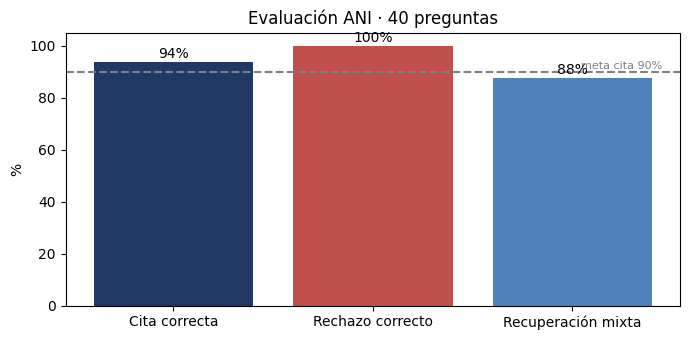


Fallos para revisar:
  #23 [cita] ¿Cuántos días máximo pueden suspender a mi hijo?
  #37 [cita, mixta, art. inventado 39] Si el reglamento del liceo dice algo distinto al decreto del ministerio, ¿cuál vale?

Guardado en Drive: ANI_resultados_evaluacion_v8.xlsx y ANI_metricas_v8.png


In [15]:
# ============================================================
# 9 · EVALUACIÓN 1/2: ANI responde las 40 preguntas del set de prueba + métricas de cita y rechazo
#   Requisito: ANI_set_preguntas_prueba.xlsx en la carpeta ANI. Gasta 1-3 consultas por pregunta.
#   Si se corta (cuota o 503), vuelve a ejecutar: retoma donde quedó (las respuestas se guardan en Drive).
#   Versiones anteriores (v1, v2, v3) quedaron medidas en el notebook de iteraciones.
# ============================================================
import glob, os, re, time, json
import pandas as pd
import matplotlib.pyplot as plt

PAUSA = 6        # segundos entre preguntas (evita el error 429 de la cuota gratuita)
VERSION = "v8"   # versión final (cambia el nombre si vuelves a medir tras otro cambio)
SUFIJO = "" if VERSION == "v1" else f"_{VERSION}"

# ---------- 1. Cargar preguntas ----------
candidatos = (glob.glob(os.path.join(CARPETA, "ANI_set_preguntas_prueba*.xlsx")) +
              glob.glob(os.path.join(os.path.dirname(CARPETA), "ANI_set_preguntas_prueba*.xlsx")))
if not candidatos:
    raise FileNotFoundError("No encontré ANI_set_preguntas_prueba.xlsx ni en la carpeta ANI ni en la del proyecto.")
archivo = sorted(candidatos)[-1]
df = pd.read_excel(archivo, sheet_name="Preguntas")
df.columns = ["n", "pregunta", "dominio", "doc_esperado", "pagina", "rechazar",
              "mixta", "capacidad", "resp_esperada", "revision"][:len(df.columns)]
df["pagina"] = df["pagina"].fillna("").astype(str)
print(f"{len(df)} preguntas cargadas desde {os.path.basename(archivo)}")

# ---------- 2. Funciones de evaluación ----------
def paginas(texto):
    """'19-20' -> {19, 20}; '62 / 70' -> {62, 70}; '17.0' -> {17}"""
    s = set()
    for a, b in re.findall(r"(\d+)(?:\.0)?\s*(?:[-–]\s*(\d+))?", str(texto)):
        a = int(a); b = int(b) if b else a
        s.update(range(a, b + 1))
    return s

def fuentes(respuesta):
    """Lista de (documento | ubicación, {páginas}), separando fuentes unidas con ';'"""
    out = []
    for linea in respuesta.splitlines():
        if "Fuente" not in linea:
            continue
        doc = ""
        for parte in linea.split(";"):
            if doc_clave(parte):
                doc = parte.split(",")[0]
            m = re.findall(r"p[áa]gs?\.?\s*([\d\s,\-–y]+)", parte)
            out.append((f"{doc} | {parte}", set().union(*map(paginas, m)) if m else set()))
    return out

def doc_clave(texto):
    claves = []
    if "Evaluaci" in texto: claves.append("Evaluaci")
    if "Convivencia" in texto: claves.append("Convivencia")
    if "Decreto" in texto: claves.append("Decreto")
    return claves

def cita_correcta(respuesta, doc_esp, pag_esp):
    """El documento interno esperado aparece citado y la página calza (tolerancia ±1)."""
    esperado = [c for c in doc_clave(doc_esp) if c != "Decreto"] or doc_clave(doc_esp)
    pags_esp = paginas(pag_esp)
    for linea, pags in fuentes(respuesta):
        if any(c in linea for c in esperado):
            if not pags_esp:
                return True
            if any(abs(p - q) <= 1 for p in pags for q in pags_esp):
                return True
    return False

RECHAZO = "no está regulado"
def rechazo(respuesta):
    return RECHAZO in respuesta.lower()

# Artículos que existen en el corpus (para detectar artículos inventados)
ARTS_CORPUS = set()
for f in fragmentos:
    for t in (f["texto"], f["ubicacion"]):
        ARTS_CORPUS.update(re.findall(r"Art[íi]culo\s+(\d+)", t))
        ARTS_CORPUS.update(re.findall(r"Art\.\s*(\d+)", t))

def articulos_inventados(respuesta):
    citados = set(re.findall(r"Art(?:[íi]culo|\.)\s*(\d+)", respuesta))
    return sorted(citados - ARTS_CORPUS, key=int)

# ---------- 3. Correr las preguntas (con retoma) ----------
salida = os.path.join(CARPETA, f"ANI_resultados_evaluacion{SUFIJO}.json")
resultados = json.load(open(salida, encoding="utf-8")) if os.path.exists(salida) else {}

fallos_seguidos = 0
for _, fila in df.iterrows():
    clave = str(int(fila["n"]))
    if clave in resultados and resultados[clave]["modelo"]:
        continue
    if fallos_seguidos >= 3:
        print("⛔ 3 fallos seguidos: se acabó la cuota. Vuelve a ejecutar más tarde (retoma desde aquí).")
        break
    agente_eval = AgenteANI()                     # memoria limpia para cada pregunta
    inicio = time.time()
    texto, modelo = agente_eval.preguntar(fila["pregunta"])
    herramientas = [t["herramienta"] for t in traza]
    resultados[clave] = {"respuesta": texto, "modelo": modelo,
                         "segundos": round(time.time() - inicio, 1),
                         "herramientas": herramientas,
                         "consultas": [{"herramienta": t["herramienta"], "consulta": t["consulta"],
                                        "dominio": t.get("dominio")} for t in traza if "consulta" in t]}
    json.dump(resultados, open(salida, "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    print(f"[{clave:>2}/{len(df)}] {resultados[clave]['segundos']:>5}s · {', '.join(herramientas) or 'sin herramientas'}")
    fallos_seguidos = 0 if modelo else fallos_seguidos + 1
    time.sleep(PAUSA)

# ---------- 4. Calcular métricas ----------
pendientes = [str(int(n)) for n in df["n"] if not resultados.get(str(int(n)), {}).get("modelo")]
if pendientes:
    raise RuntimeError(f"Faltan {len(pendientes)} preguntas ({', '.join(pendientes)}). "
                       "Vuelve a ejecutar esta celda cuando se recupere la cuota.")
filas = []
for _, fila in df.iterrows():
    r = resultados[str(int(fila["n"]))]
    resp = r["respuesta"]
    debe_rechazar = str(fila["rechazar"]).strip().lower() in ("sí", "si")
    es_mixta = str(fila["mixta"]).strip().lower() in ("sí", "si")
    rechazo_ok = rechazo(resp) if debe_rechazar else not rechazo(resp)
    cita_ok = None if debe_rechazar else cita_correcta(resp, fila["doc_esperado"], fila["pagina"])
    mixta_ok = None
    if es_mixta:
        cito = " ".join(l for l, _ in fuentes(resp))
        mixta_ok = ("buscar_norma_interna" in r["herramientas"] and "buscar_norma_externa" in r["herramientas"]
                    and "Decreto" in cito and ("Evaluaci" in cito or "Convivencia" in cito))
    filas.append({**fila.to_dict(), "respuesta_ANI": resp, "modelo": r["modelo"], "segundos": r["segundos"],
                  "herramientas": ", ".join(r["herramientas"]), "cita_correcta": cita_ok,
                  "rechazo_correcto": rechazo_ok, "mixta_recuperada": mixta_ok,
                  "articulos_inventados": ", ".join(articulos_inventados(resp)),
                  "¿Contenido correcto? (manual)": ""})
res = pd.DataFrame(filas)

normales = res[res["cita_correcta"].notna()]
rech = res[res["rechazar"].astype(str).str.lower().isin(["sí", "si"])]
mixtas = res[res["mixta_recuperada"].notna()]
falsos_rechazos = (~res.loc[~res.index.isin(rech.index), "rechazo_correcto"].astype(bool)).sum()
n_inventados = sum(len(a.split(", ")) for a in res["articulos_inventados"] if a)

metricas = pd.DataFrame([
    ["Cita correcta", normales["cita_correcta"].astype(bool).mean() * 100, "≥ 90%", f"{normales['cita_correcta'].astype(bool).sum()}/{len(normales)}"],
    ["Rechazo correcto", rech["rechazo_correcto"].astype(bool).mean() * 100, "100%", f"{rech['rechazo_correcto'].astype(bool).sum()}/{len(rech)}"],
    ["Recuperación mixta", mixtas["mixta_recuperada"].astype(bool).mean() * 100, "—", f"{mixtas['mixta_recuperada'].astype(bool).sum()}/{len(mixtas)}"],
    ["Artículos inventados", n_inventados, "0", "artículos"],
    ["Falsos rechazos", falsos_rechazos, "0", "preguntas"],
    ["Tiempo promedio (s)", res["segundos"].mean(), "—", "segundos"],
], columns=["Métrica", "Valor", "Meta", "Detalle"])
metricas["Valor"] = metricas["Valor"].round(1)
print("\n", metricas.to_string(index=False))

# ---------- 5. Guardar Excel + gráfico para el informe ----------
xlsx = os.path.join(CARPETA, f"ANI_resultados_evaluacion{SUFIJO}.xlsx")
with pd.ExcelWriter(xlsx) as w:
    metricas.to_excel(w, sheet_name="Métricas", index=False)
    res.to_excel(w, sheet_name="Detalle", index=False)

fig, ax = plt.subplots(figsize=(7, 3.5))
nombres = ["Cita correcta", "Rechazo correcto", "Recuperación mixta"]
valores = metricas.set_index("Métrica").loc[nombres, "Valor"]
barras = ax.bar(nombres, valores, color=["#1F3864", "#C0504D", "#4F81BD"])
ax.axhline(90, ls="--", color="gray"); ax.text(2.45, 91, "meta cita 90%", ha="right", fontsize=8, color="gray")
ax.set_ylim(0, 105); ax.set_ylabel("%"); ax.set_title(f"Evaluación ANI · {len(res)} preguntas")
for b, v in zip(barras, valores):
    ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.0f}%", ha="center")
plt.tight_layout(); plt.savefig(os.path.join(CARPETA, f"ANI_metricas{SUFIJO}.png"), dpi=200); plt.show()

print("\nFallos para revisar:")
for _, f in res.iterrows():
    problemas = []
    if f["cita_correcta"] is not None and pd.notna(f["cita_correcta"]) and not f["cita_correcta"]: problemas.append("cita")
    if not f["rechazo_correcto"]: problemas.append("rechazo")
    if f["mixta_recuperada"] is not None and pd.notna(f["mixta_recuperada"]) and not f["mixta_recuperada"]: problemas.append("mixta")
    if f["articulos_inventados"]: problemas.append(f"art. inventado {f['articulos_inventados']}")
    if problemas:
        print(f"  #{int(f['n'])} [{', '.join(problemas)}] {f['pregunta']}")
print(f"\nGuardado en Drive: {os.path.basename(xlsx)} y ANI_metricas{SUFIJO}.png")

40 preguntas · respuestas de ANI versión v8

=== Evaluación IL1.4 · versión v8 ===
                    Métrica  Valor Umbral ¿Cumple?
Exactitud vs referencia (%)   97.5     80        ✅
   Fidelidad promedio (/10)    9.8      8        ✅
  Relevancia promedio (/10)    9.8      8        ✅
      Context Precision (%)   31.7     50        ❌
         Context Recall (%)   96.9     80        ✅
  Hit@k página esperada (%)   96.9     80        ✅
       Rechazo correcto (%)  100.0    100        ✅
       Latencia mediana (s)   28.4      —        —

Veredicto: 6/7 criterios cumplidos → FUNCIONA PARCIALMENTE

Diagnóstico por componente (qué falla):
diagnostico
OK                                          38
rechazo mal resuelto                         1
falla de RECUPERACIÓN (el dato no llegó)     1

Preguntas con problemas:
  #28 [rechazo mal resuelto] ¿Me recomiendas un preuniversitario para la PAES?
       → Aunque indica correctamente que no está regulado, el sistema añade una sugerencia operativ

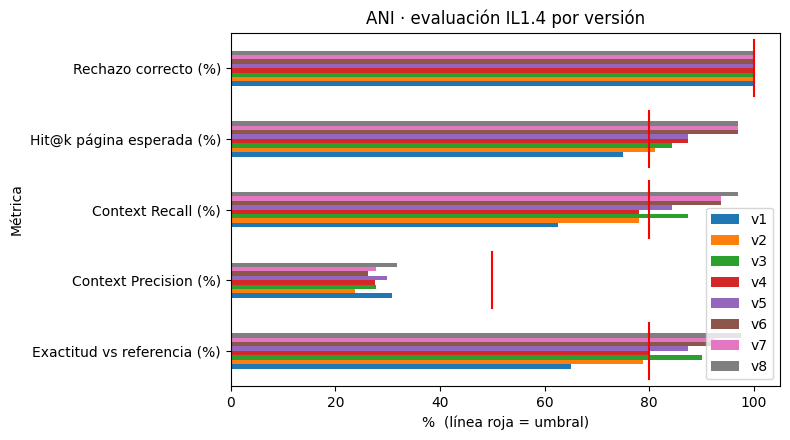


Guardado en Drive: ANI_evaluacion_IL14_v8.xlsx y ANI_evaluacion_IL14.png


In [16]:
# ============================================================
# 10 · EVALUACIÓN 2/2: juez LLM con los criterios de RA1 · IL1.4 + comparación v1 → v4
#   Recuperación: Context Precision, Context Recall, Hit@k · Generación: fidelidad, relevancia, exactitud
#   El juez es un LLM a temperatura 0 que compara con la respuesta de referencia. Gasta 1 consulta por pregunta.
# ============================================================
import os, re, json, time, glob
import pandas as pd
import matplotlib.pyplot as plt

VERSION = "v8"                              # misma versión de la celda anterior
SUFIJO = "" if VERSION == "v1" else f"_{VERSION}"
JUECES = ["gemini-3.8-flash", "gemini-3.5-flash-lite", "gemini-3.1-flash-lite"] # distinto al que responde, si hay cuota
PAUSA = 4
MAX_CHARS = 4000                              # por fragmento, para no reventar el contexto del juez

# Umbrales para decir "funciona" (definidos por el equipo; el curso no fija valores)
UMBRALES = {
    "Exactitud vs referencia (%)": 80,
    "Fidelidad promedio (/10)": 8,
    "Relevancia promedio (/10)": 8,
    "Context Precision (%)": 50,
    "Context Recall (%)": 80,
    "Hit@k página esperada (%)": 80,
    "Rechazo correcto (%)": 100,
}

# ---------- 1. Cargar preguntas y respuestas del Paso 19 ----------
candidatos = (glob.glob(os.path.join(CARPETA, "ANI_set_preguntas_prueba*.xlsx")) +
              glob.glob(os.path.join(os.path.dirname(CARPETA), "ANI_set_preguntas_prueba*.xlsx")))
df = pd.read_excel(sorted(candidatos)[-1], sheet_name="Preguntas")
df.columns = ["n", "pregunta", "dominio", "doc_esperado", "pagina", "rechazar",
              "mixta", "capacidad", "resp_esperada", "revision"][:len(df.columns)]
df["pagina"] = df["pagina"].fillna("").astype(str)
resp = json.load(open(os.path.join(CARPETA, f"ANI_resultados_evaluacion{SUFIJO}.json"), encoding="utf-8"))
print(f"{len(df)} preguntas · respuestas de ANI versión {VERSION}")

def paginas(texto):
    s = set()
    for a, b in re.findall(r"(\d+)(?:\.0)?\s*(?:[-–]\s*(\d+))?", str(texto)):
        a = int(a); b = int(b) if b else a
        s.update(range(a, b + 1))
    return s

def doc_clave(texto):
    return [c for c in ("Evaluaci", "Convivencia", "Decreto") if c in str(texto)]

SINONIMO = {"evaluación": "evaluacion", "convivencia": "convivencia"}

# ---------- 2. Reconstruir el contexto que recuperó el agente ----------
# Los embeddings son locales (e5-small): re-buscar no gasta cuota de Gemini.
def contexto(fila, r):
    PREGUNTA_ACTUAL["texto"] = fila["pregunta"]      # el buscador también usa la pregunta original
    frs = []
    consultas = r.get("consultas")
    if consultas:                                   # consultas reales del agente
        for c in consultas:
            if c["herramienta"] == "buscar_norma_interna":
                frs += buscar(c["consulta"], "interna", k=4, dominio=c.get("dominio"))
            elif c["herramienta"] == "buscar_norma_externa":
                frs += buscar(c["consulta"], "externa", k=3)
    else:                                           # resultados antiguos: aproxima con la pregunta
        dom = SINONIMO.get(fila["dominio"])
        if "buscar_norma_interna" in r["herramientas"]:
            frs += buscar(fila["pregunta"], "interna", k=4, dominio=dom)
        if "buscar_norma_externa" in r["herramientas"]:
            frs += buscar(fila["pregunta"], "externa", k=3)
    PREGUNTA_ACTUAL["texto"] = ""
    vistos, unicos = set(), []
    for f in frs:
        clave = (f["documento"], f["ubicacion"], f["paginas"], f["texto"][:50])
        if clave not in vistos:
            vistos.add(clave); unicos.append(f)
    return unicos

def hit_pagina(frs, doc_esp, pag_esp):
    """¿Algún fragmento recuperado es del documento esperado y cubre la página (±1)?"""
    esperado = [c for c in doc_clave(doc_esp) if c != "Decreto"] or doc_clave(doc_esp)
    pe = paginas(pag_esp)
    for f in frs:
        if any(c in f["documento"] for c in esperado):
            if not pe or any(abs(p - q) <= 1 for p in paginas(f["paginas"]) for q in pe):
                return True
    return False

# ---------- 3. El juez ----------
PROMPT_JUEZ = """Eres un evaluador estricto de un sistema RAG que responde dudas de apoderados sobre reglamentos escolares.

PREGUNTA: {pregunta}

RESPUESTA DE REFERENCIA (correcta): {referencia}

FRAGMENTOS RECUPERADOS:
{fragmentos}

RESPUESTA DEL SISTEMA:
{respuesta}

Evalúa y responde SOLO con un JSON con estas claves:
- "fidelidad": entero 1-10. ¿Todo lo que afirma la respuesta está respaldado por los FRAGMENTOS? (1-3 inventa o contradice, 4-6 parcialmente, 7-10 totalmente). Si la respuesta solo dice que no está regulado, evalúa si eso es coherente con los fragmentos.
- "relevancia": entero 1-10. ¿Responde de forma directa y útil lo que preguntó el apoderado?
- "exactitud": "CORRECTO", "PARCIAL" o "INCORRECTO" comparando con la RESPUESTA DE REFERENCIA (no exijas coincidencia literal; un plazo, número o responsable distinto es INCORRECTO).
- "fragmentos_relevantes": lista con los números de los fragmentos útiles para responder (ej: [1, 3]); [] si ninguno.
- "contexto_suficiente": true si los fragmentos contienen la información de la referencia, false si no.
- "comentario": una frase con el problema principal, o "" si no hay."""

def juzgar(fila, r, frs):
    fragmentos = "\n\n".join(f"[F{i+1}] {f['documento']} | {f['ubicacion']} | pág. {f['paginas']}\n{f['texto'][:MAX_CHARS]}"
                             for i, f in enumerate(frs)) or "(ninguno: el agente no buscó)"
    prompt = PROMPT_JUEZ.format(pregunta=fila["pregunta"], referencia=fila["resp_esperada"],
                                fragmentos=fragmentos, respuesta=r["respuesta"])
    cfg = types.GenerateContentConfig(temperature=0, response_mime_type="application/json")
    for modelo in JUECES:
        for intento in range(3):
            try:
                out = client.models.generate_content(model=modelo, contents=prompt, config=cfg)
                datos = json.loads(re.sub(r"```json|```", "", out.text).strip())
                datos["juez"] = modelo
                return datos
            except Exception as e:
                error = str(e)
                if "PerDay" in error:
                    break
                if any(x in error for x in ("429", "503", "UNAVAILABLE")):
                    time.sleep(10 * (intento + 1)); continue
                if isinstance(e, json.JSONDecodeError):
                    continue
                raise
    return None

# ---------- 4. Correr el juez (con retoma) ----------
salida = os.path.join(CARPETA, f"ANI_juez_IL14{SUFIJO}.json")
juicios = json.load(open(salida, encoding="utf-8")) if os.path.exists(salida) else {}
fallos = 0
for _, fila in df.iterrows():
    k = str(int(fila["n"]))
    if k in juicios:
        continue
    if fallos >= 3:
        print("⛔ El juez se quedó sin cuota. Vuelve a ejecutar más tarde (retoma desde aquí)."); break
    r = resp[k]
    frs = contexto(fila, r)
    j = juzgar(fila, r, frs)
    if j is None:
        fallos += 1; continue
    fallos = 0
    j["n_fragmentos"] = len(frs)
    j["hit_pagina"] = hit_pagina(frs, fila["doc_esperado"], fila["pagina"])
    juicios[k] = j
    json.dump(juicios, open(salida, "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    print(f"[{k:>2}/{len(df)}] {j['exactitud']:<10} fid {j['fidelidad']:>2} · rel {j['relevancia']:>2} · {j['juez']}")
    time.sleep(PAUSA)

faltan = [str(int(n)) for n in df["n"] if str(int(n)) not in juicios]
if faltan:
    raise RuntimeError(f"Faltan {len(faltan)} juicios ({', '.join(faltan)}). Vuelve a ejecutar cuando haya cuota.")

# ---------- 5. Métricas IL1.4 ----------
filas = []
for _, fila in df.iterrows():
    k = str(int(fila["n"])); j = juicios[k]; r = resp[k]
    rechazo = str(fila["rechazar"]).strip().lower() in ("sí", "si")
    nfr = j["n_fragmentos"]
    prec = (len(set(j["fragmentos_relevantes"]) & set(range(1, nfr + 1))) / nfr) if (nfr and not rechazo) else None
    exact = {"CORRECTO": 1, "PARCIAL": 0.5, "INCORRECTO": 0}.get(str(j["exactitud"]).upper(), 0)
    # Diagnóstico IL1.4: ¿falla el recuperador o el generador?
    if exact == 1 and j["fidelidad"] >= 7:
        diag = "OK"
    elif rechazo:
        diag = "rechazo mal resuelto"
    elif not j["contexto_suficiente"]:
        diag = "falla de RECUPERACIÓN (el dato no llegó)"
    elif j["fidelidad"] < 7:
        diag = "falla de GENERACIÓN (alucina)"
    else:
        diag = "falla de GENERACIÓN (tenía el dato y no lo usó)"
    filas.append({"n": int(fila["n"]), "pregunta": fila["pregunta"], "capacidad": fila["capacidad"],
                  "respuesta_esperada": fila["resp_esperada"], "respuesta_ANI": r["respuesta"],
                  "exactitud": j["exactitud"], "exactitud_num": exact, "fidelidad": j["fidelidad"],
                  "relevancia": j["relevancia"], "context_precision": prec,
                  "context_recall": None if rechazo else bool(j["contexto_suficiente"]),
                  "hit_pagina": None if rechazo else bool(j["hit_pagina"]),
                  "rechazo_ok": ("no está regulado" in r["respuesta"].lower()) if rechazo else None,
                  "segundos": r["segundos"], "diagnostico": diag, "comentario_juez": j.get("comentario", ""),
                  "juez": j["juez"]})
res = pd.DataFrame(filas)
nr = res[res["context_recall"].notna()]

valores = {
    "Exactitud vs referencia (%)": res["exactitud_num"].mean() * 100,
    "Fidelidad promedio (/10)": res["fidelidad"].mean(),
    "Relevancia promedio (/10)": res["relevancia"].mean(),
    "Context Precision (%)": nr["context_precision"].astype(float).mean() * 100,
    "Context Recall (%)": nr["context_recall"].astype(bool).mean() * 100,
    "Hit@k página esperada (%)": nr["hit_pagina"].astype(bool).mean() * 100,
    "Rechazo correcto (%)": res["rechazo_ok"].dropna().astype(bool).mean() * 100,
}
metricas = pd.DataFrame([{"Métrica": m, "Valor": round(v, 1), "Umbral": UMBRALES[m],
                          "¿Cumple?": "✅" if v >= UMBRALES[m] else "❌"} for m, v in valores.items()])
metricas.loc[len(metricas)] = ["Latencia mediana (s)", round(res["segundos"].median(), 1), "—", "—"]
print(f"\n=== Evaluación IL1.4 · versión {VERSION} ===")
print(metricas.to_string(index=False))

cumple = (metricas["¿Cumple?"] == "✅").sum(); total = len(UMBRALES)
print(f"\nVeredicto: {cumple}/{total} criterios cumplidos →",
      "FUNCIONA" if cumple == total else "FUNCIONA PARCIALMENTE" if cumple >= total / 2 else "NO FUNCIONA AÚN")

print("\nDiagnóstico por componente (qué falla):")
print(res["diagnostico"].value_counts().to_string())
print("\nPreguntas con problemas:")
for _, f in res[res["diagnostico"] != "OK"].iterrows():
    print(f"  #{f['n']:>2} [{f['diagnostico']}] {f['pregunta']}\n       → {f['comentario_juez']}")
    print("       ANI dijo: " + f["respuesta_ANI"].replace("\n", " ")[:300] + "…")

# ---------- 6. Guardar + comparar versiones ----------
xlsx = os.path.join(CARPETA, f"ANI_evaluacion_IL14{SUFIJO}.xlsx")
with pd.ExcelWriter(xlsx) as w:
    metricas.to_excel(w, sheet_name="Métricas", index=False)
    res.to_excel(w, sheet_name="Detalle", index=False)

comparacion = {}
for archivo in sorted(glob.glob(os.path.join(CARPETA, "ANI_evaluacion_IL14*.xlsx"))):
    m = re.search(r"IL14_?(v\d+)?\.xlsx$", archivo)
    ver = (m.group(1) if m and m.group(1) else "v1")
    tabla = pd.read_excel(archivo, sheet_name="Métricas").set_index("Métrica")["Valor"]
    comparacion[ver] = tabla
comp = pd.DataFrame(comparacion).loc[list(UMBRALES)]
if comp.shape[1] > 1:
    print("\nComparación entre versiones:")
    print(comp.to_string())

pct = [m for m in UMBRALES if "%" in m]
ax = comp.loc[pct].plot(kind="barh", figsize=(8, 4.5))
for i, m in enumerate(pct):
    ax.plot([UMBRALES[m]] * 2, [i - 0.4, i + 0.4], color="red", lw=1.5)
ax.set_xlim(0, 105); ax.set_xlabel("%  (línea roja = umbral)")
ax.set_title("ANI · evaluación IL1.4 por versión"); plt.tight_layout()
plt.savefig(os.path.join(CARPETA, "ANI_evaluacion_IL14.png"), dpi=200); plt.show()
print(f"\nGuardado en Drive: {os.path.basename(xlsx)} y ANI_evaluacion_IL14.png")